# Understand our PaddleOCR training results

**Run this notebook from top to bottom on your Mac. No training, GPU, PaddleOCR installation or model download is needed.**

This is a visual explanation of the eight runs completed on 6–7 November 2026. It reads the saved predictions and training logs. The crop viewer opens the original training-package ZIP without extracting it or changing it.

**Added 11 Nov:** section **4c** (the step-by-step ladder with the new C0 run), **7c** (the mobile reader, batch A) and **7d** (the final model S1his on the teammate's 80:10:10 split). These read `results_server_c0_20261111`, `results_mobile_official_20261110` and `results_server_his_20261110`.

**What you will see:** what each run changed → overall results → actual images and readings → pooling comparison → training curves → augmentation comparisons → a CTC exercise → **training-strategy experiments (S0–S3, G0, 7 Nov)** → next steps.

The image comparisons replay **saved checkpoint predictions**, rather than run a new model. They show recognition on existing line crops; they do not evaluate the full-photo text detector or preprocessing pipeline.

In [1]:
from pathlib import Path
from collections import defaultdict
from functools import lru_cache
import csv, difflib, html, io, json, math, random, re, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, HTML, Markdown

# Usually automatic. If you move the notebook elsewhere, set this to your Assignment folder.
ASSIGNMENT_OVERRIDE = None
roots = []
for base in [Path.cwd(), *Path.cwd().parents]:
    roots.extend([base, base / 'Assignment'])
if ASSIGNMENT_OVERRIDE:
    roots.insert(0, Path(ASSIGNMENT_OVERRIDE).expanduser())
ASSIGNMENT = next((p.resolve() for p in roots
    if (p / 'results_versions_2x2/results/predictions.csv').is_file()), None)
if ASSIGNMENT is None:
    raise FileNotFoundError('Set ASSIGNMENT_OVERRIDE to the Assignment folder containing results_versions_2x2.')

RESULTS = ASSIGNMENT / 'results_versions_2x2'
df = pd.read_csv(RESULTS / 'results/predictions.csv', keep_default_na=False)
saved = json.loads((RESULTS / 'results/summary.json').read_text())
assert not df.duplicated(['model', 'set', 'file']).any(), 'Duplicate prediction keys.'
MODELS = [m for m in ['V1','pretrained','V1b','V2short','V3short','V2','V3','C1','P40','P128'] if m in set(df.model)]
SETS = ['CNN test', 'long sentences (held out)', 'whiteboard val', 'IAM val']
for st in SETS:
    groups = df[df['set'].eq(st)].groupby('model')
    signatures = [set(zip(g.file, g.label, g.cluster)) for _, g in groups]
    assert all(s == signatures[0] for s in signatures), f'Different crops/labels in {st}'

summary = (df.groupby(['model','set'], sort=False)
    .agg(crops=('cer','size'), mean_CER=('cer','mean'), errors=('err','sum'),
         characters=('chars','sum'), exact=('exact_case','mean'), repeats=('extra_repeats','mean')))
summary['corpus_CER'] = summary.errors / summary.characters.clip(lower=1)
for (model, st), row in summary.iterrows():
    assert abs(row.mean_CER - saved['summary'][f'{model} | {st}']['mean_line_CER']) < 1e-10

plt.rcParams.update({'figure.dpi': 115, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})
pd.set_option('display.max_colwidth', 95)
print('Assignment folder:', ASSIGNMENT)
print(f'{len(df):,} saved prediction rows loaded; summary and matched-crop checks passed.')
print('Read-only viewer: no training or inference will start.')

Assignment folder: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment
13,840 saved prediction rows loaded; summary and matched-crop checks passed.
Read-only viewer: no training or inference will start.


## 1. What did we train?

Your professor asked for adaptation **inside PaddleOCR**, supported by comparisons. We investigated the data recipe and the recognizer's horizontal feature representation.

Each run below started independently from the **same downloaded pretrained recognizer**. These are not successive stages of one checkpoint.

**V1** is the historical `Baseline_model` (13 October), read the way it was deployed (48 px high, width follows the crop). It is shown in the score tables only as the starting point of the project; it was not trained with this recipe, so it is not part of the controlled comparisons. All training runs used built-in RecAug; “extra augmentation” means our additional saved copies.

In [2]:
DESCRIPTIONS = {
 'V1b':'IAM only; adapted wide-input recipe',
 'V2short':'A: our data; labels <=40 characters; no extra copies',
 'V3short':'B: same short-only data + extra augmented copies',
 'V2':'C: our data including long lines; no extra copies',
 'V3':'D: same short + long data + extra augmented copies',
 'C1':'V3 data; original geometry/pooling recipe (48 x 320)',
 'P40':'Wide input; original 40-position training pooling; matched subset',
 'P128':'Same subset/input as P40; width-proportional training pooling',
}
run_rows = []
for model, description in DESCRIPTIONS.items():
    done = json.loads((RESULTS / 'runs' / model / 'DONE').read_text())
    plan = done['plan']
    run_rows.append({'Run':model, 'Question / recipe':description,
        'Training entries':plan['lines'], 'Actual updates':plan['planned_updates'],
        'Minutes':round(done['minutes'],1)})
display(pd.DataFrame(run_rows).set_index('Run'))
display(Markdown('**Budget note:** approximately 6,000 updates per run, not exactly equal. '
    'P40 and P128 have identical training-list hashes and matched budgets. '
    'Repeated/augmented entries are not independent new handwriting samples.'))

,Question / recipe,Training entries,Actual updates,Minutes
Run,,,,
V1b,IAM only; adapted wide-input recipe,6482,6090,22.0
V2short,A: our data; labels <=40 characters; no extra copies,1118,6020,23.2
V3short,B: same short-only data + extra augmented copies,4289,5918,21.6
V2,C: our data including long lines; no extra copies,1423,5963,23.9
V3,D: same short + long data + extra augmented copies,5500,5848,21.9
C1,V3 data; original geometry/pooling recipe (48 x 320),4269,5874,6.5
P40,Wide input; original 40-position training pooling; matched subset,4269,5874,12.9
P128,Same subset/input as P40; width-proportional training pooling,4269,5874,21.3


**Budget note:** approximately 6,000 updates per run, not exactly equal. P40 and P128 have identical training-list hashes and matched budgets. Repeated/augmented entries are not independent new handwriting samples.

## 2. Did recognition improve?

**CER = character edit distance ÷ ground-truth character count. Lower is better.** It counts substitutions, insertions and deletions. It is not classification accuracy and can exceed 100% if many characters are inserted.

The charts use **mean line CER**, averaging the crop CERs. Corpus CER weights long lines more heavily and is available in `summary`. Scores ignore case and normalise spaces; exact-match scores in the saved report are case-sensitive.

,CNN test CER (%),long sentences (held out) CER (%),whiteboard val CER (%),IAM val CER (%)
Model,,,,
V1,81.32,84.94,90.59,79.46
pretrained,45.79,30.93,15.48,12.20
V1b,49.76,5.79,16.77,7.79
V2short,28.57,5.81,7.25,27.06
V3short,25.83,4.49,7.13,21.08
V2,23.72,2.38,7.31,23.26
V3,24.27,2.65,7.18,25.71
C1,28.72,8.81,9.30,31.40
P40,93.88,45.26,54.54,60.98


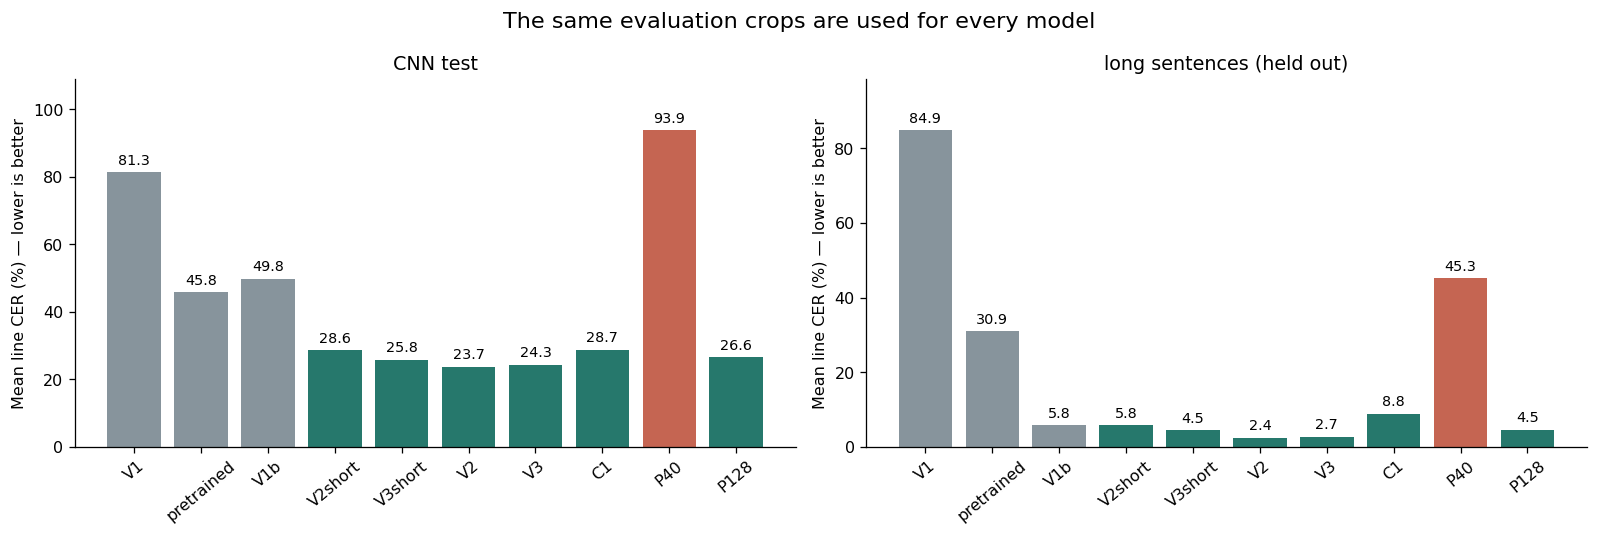

**Read this carefully:** P128 has the lowest whiteboard-validation CER; V2 has lower CNN/held-out-sentence test CER. Do not choose settings by the test winner. CNN has **7 texts across 38 photo clusters**. The sentence test has **7 sentences from one writer/board**, and some labels await review. These are encouraging results, not proof of generalisation to everyone. The separate >40-character report view reuses 41 of the 57 sentence crops; it is not another independent test.

In [3]:
score_table = pd.DataFrame({st: [100 * summary.loc[(m, st),'mean_CER'] for m in MODELS]
    for st in SETS}, index=MODELS)
score_table.index.name = 'Model'
display(score_table.rename(columns=lambda x: x + ' CER (%)').round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
for ax, st in zip(axes, SETS[:2]):
    vals = score_table[st]
    colors = ['#87949c' if m in ['V1','pretrained','V1b'] else '#c56552' if m=='P40' else '#26786c' for m in MODELS]
    bars = ax.bar(MODELS, vals, color=colors)
    ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)
    ax.set(title=st, ylabel='Mean line CER (%) — lower is better', ylim=(0, max(vals)*1.16))
    ax.tick_params(axis='x', rotation=40)
fig.suptitle('The same evaluation crops are used for every model', fontsize=14)
fig.tight_layout()
plt.show()

display(Markdown('**Read this carefully:** P128 has the lowest whiteboard-validation CER; '
    'V2 has lower CNN/held-out-sentence test CER. Do not choose settings by the test winner. '
    'CNN has **7 texts across 38 photo clusters**. The sentence test has **7 sentences from one writer/board**, '
    'and some labels await review. These are encouraging results, not proof of generalisation to everyone. '
    'The separate >40-character report view reuses 41 of the 57 sentence crops; it is not another independent test.'))

## 3. Look at an actual crop and compare the readings

The first comparison uses a fixed random order. You can then choose models, sets and examples below. **The ground truth is the saved annotation**, not an answer supplied by the viewer; some annotations still require review.

Green characters match the normalised label; red characters are edits. A crossed-out red character is missing from the prediction. Alignment is a diagnostic and can be ambiguous.

Image lookup: 367/367 whiteboard evaluation crops found.
CNN test | example 1/174 | filter: All | order: Fixed random order
File: reader__images__wb__cnn_47_015.png


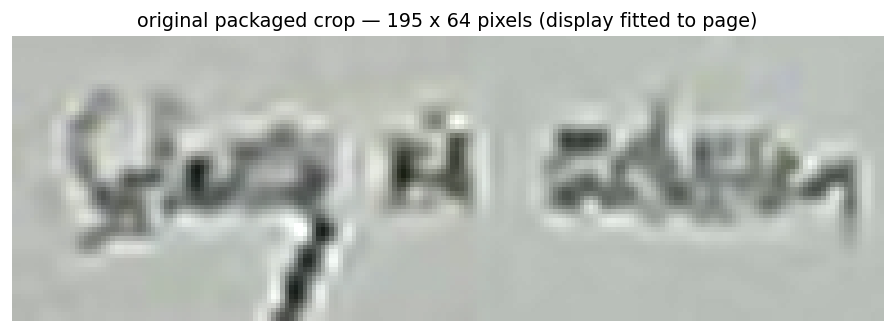

Model,Saved reading,Line CER
pretrained,Se,90.9%
,saliency via occlusion,
V2,Sitiang in modtunsion,54.5%
,sitiancg vin modtunsion,


long sentences (held out) | example 1/57 | filter: All | order: Fixed random order
File: reader__images__long__IMG_4959__robot_project_05.png


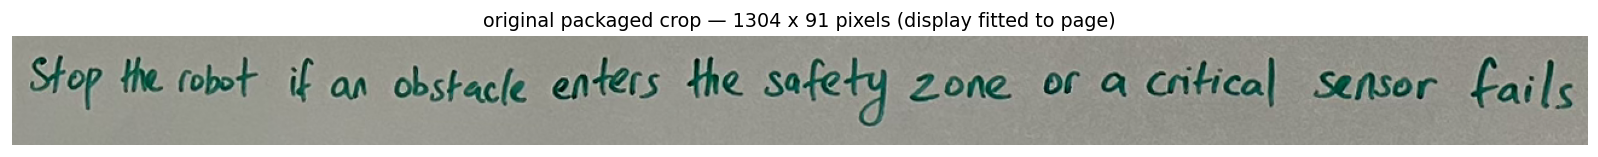

Model,Saved reading,Line CER
pretrained,Stop the obotifaobtees tesaetyzoeoracialsoris,43.0%
,stop the robot if an obstacle enters the safety zone or a critical sensor fails,
V2,Stop the robot if an obstacle enters the safety zone or a critical sensor fails,0.0%
,stop the robot if an obstacle enters the safety zone or a critical sensor fails,


In [4]:
ZIP_PATH = ASSIGNMENT / 'board2notes_versions_runpod/b2n_versions_data.zip'
image_index = {}
if ZIP_PATH.is_file():
    with zipfile.ZipFile(ZIP_PATH) as z:
        for name in z.namelist():
            if name.startswith('b2n_data/') and name.lower().endswith(('.png','.jpg','.jpeg','.bmp','.webp')):
                key = name[len('b2n_data/'):].replace('/', '__')
                assert key not in image_index, f'Ambiguous archive filename: {key}'
                image_index[key] = name
else:
    print('Original ZIP missing. Results tables still work; trying local image copies instead.')
local_index = {}
local_root = ASSIGNMENT / 'board2notes_reader_dataset_20261105'
if local_root.is_dir():
    local_index = {('reader/' + p.relative_to(local_root).as_posix()).replace('/', '__'):p
                   for p in (local_root/'images').rglob('*') if p.is_file()}

@lru_cache(maxsize=30)
def load_crop(file):
    if file in image_index:
        with zipfile.ZipFile(ZIP_PATH) as z:
            with Image.open(io.BytesIO(z.read(image_index[file]))) as im:
                return ImageOps.exif_transpose(im).convert('RGB').copy(), 'original packaged crop'
    if file in local_index:
        with Image.open(local_index[file]) as im:
            return ImageOps.exif_transpose(im).convert('RGB').copy(), 'local copy (may differ from packaged version)'
    raise FileNotFoundError(f'Crop not found: {file}. Restore b2n_versions_data.zip for the original images.')

def normalise(text):
    return ' '.join(str(text).lower().split())

def coloured_reading(label, prediction):
    a, b = normalise(label), normalise(prediction)
    # Exact Levenshtein alignment, including missing reference characters.
    D = [[0]*(len(b)+1) for _ in range(len(a)+1)]
    for i in range(len(a)+1): D[i][0] = i
    for j in range(len(b)+1): D[0][j] = j
    for i in range(1,len(a)+1):
        for j in range(1,len(b)+1):
            D[i][j] = min(D[i-1][j]+1,D[i][j-1]+1,D[i-1][j-1]+(a[i-1]!=b[j-1]))
    parts=[]; i,j=len(a),len(b)
    while i or j:
        if i and j and D[i][j] == D[i-1][j-1]+(a[i-1]!=b[j-1]):
            color = '#206b3c' if a[i-1]==b[j-1] else '#b42318'
            parts.append(f'<span style="color:{color}">{html.escape(b[j-1])}</span>'); i-=1; j-=1
        elif j and D[i][j] == D[i][j-1]+1:
            parts.append(f'<span style="color:#b42318;background:#fff0ed">{html.escape(b[j-1])}</span>'); j-=1
        else:
            parts.append(f'<del style="color:#b42318">{html.escape(a[i-1])}</del>'); i-=1
    return ''.join(reversed(parts)) or '<em>empty reading</em>'

def comparison_rows(st, before, after, outcome='All', order='Fixed random order'):
    cols=['file','label','pred','cer','cluster']
    a=df[df['set'].eq(st) & df.model.eq(before)][cols]
    b=df[df['set'].eq(st) & df.model.eq(after)][cols]
    q=a.merge(b,on=['file','label','cluster'],suffixes=('_before','_after'),validate='one_to_one')
    q['gain']=q.cer_before-q.cer_after  # positive = improvement
    if outcome=='Improved': q=q[q.gain>1e-10]
    elif outcome=='Worse': q=q[q.gain < -1e-10]
    elif outcome=='Same CER': q=q[q.gain.abs()<=1e-10]
    if order=='Biggest improvement': q=q.sort_values(['gain','file'],ascending=[False,True])
    elif order=='Biggest regression': q=q.sort_values(['gain','file'],ascending=[True,True])
    elif order=='Longest label': q=q.assign(n=q.label.str.len()).sort_values(['n','file'],ascending=[False,True])
    else: q=q.sort_values('file').sample(frac=1,random_state=7)
    return q.reset_index(drop=True)

def show_pair(st='CNN test', before='pretrained', after='V2', index=0,
              outcome='All', order='Fixed random order'):
    q=comparison_rows(st,before,after,outcome,order)
    if q.empty:
        print('No examples match this filter. Choose All or another pair.'); return
    index=min(max(int(index),0),len(q)-1)
    r=q.iloc[index]
    print(f'{st} | example {index+1}/{len(q)} | filter: {outcome} | order: {order}')
    print('File:',r.file)
    try:
        im, source=load_crop(r.file)
        fig,ax=plt.subplots(figsize=(14,3.0))
        ax.imshow(im); ax.axis('off')
        ax.set_title(f'{source} — {im.width} x {im.height} pixels (display fitted to page)')
        fig.tight_layout(); plt.show()
    except FileNotFoundError as exc:
        print(exc)
    body=f'<p><b>Saved ground truth:</b> {html.escape(r.label)}</p>'
    body+='<table style="text-align:left;border-collapse:collapse;width:100%"><tr><th>Model</th><th>Saved reading</th><th>Line CER</th></tr>'
    for name, pred, cer in [(before,r.pred_before,r.cer_before),(after,r.pred_after,r.cer_after)]:
        body+=f'<tr><td style="padding:8px">{html.escape(name)}</td><td style="padding:8px;white-space:pre-wrap;font:16px monospace">{html.escape(pred)}</td><td>{cer:.1%}</td></tr>'
        body+=f'<tr><td></td><td style="padding:0 8px 12px;white-space:pre-wrap;font:16px monospace">{coloured_reading(r.label,pred)}</td><td></td></tr>'
    body+='</table>'
    direction='lower (better)' if r.gain>1e-10 else 'higher (worse)' if r.gain < -1e-10 else 'unchanged'
    body+=f'<p>After-model CER is <b>{direction}</b>; difference = {100*(r.cer_after-r.cer_before):+.2f} percentage points.</p>'
    display(HTML(body))

cv_files=set(df[df['set'].isin(SETS[:3])].file)
print(f'Image lookup: {sum(f in image_index or f in local_index for f in cv_files)}/{len(cv_files)} whiteboard evaluation crops found.')
show_pair()
show_pair(st='long sentences (held out)',before='pretrained',after='V2')

In [5]:
# Interactive browser. If widgets are unavailable, edit the show_pair(...) call above instead.
try:
    import ipywidgets as widgets
    choose_set=widgets.Dropdown(options=SETS,value='CNN test',description='Set:')
    choose_before=widgets.Dropdown(options=MODELS,value='pretrained',description='Before:')
    choose_after=widgets.Dropdown(options=MODELS,value='V2',description='After:')
    choose_outcome=widgets.Dropdown(options=['All','Improved','Worse','Same CER'],description='Filter:')
    choose_order=widgets.Dropdown(options=['Fixed random order','Biggest improvement','Biggest regression','Longest label'],description='Order:')
    choose_index=widgets.IntSlider(value=0,min=0,max=173,description='Example:',continuous_update=False)
    def adjust_range(change=None):
        q=comparison_rows(choose_set.value,choose_before.value,choose_after.value,
                          choose_outcome.value,choose_order.value)
        choose_index.max=max(0,len(q)-1)
        choose_index.value=0
    for w in [choose_set,choose_before,choose_after,choose_outcome,choose_order]: w.observe(adjust_range,names='value')
    adjust_range()
    button=widgets.Button(description='Show comparison',button_style='info')
    browser_output=widgets.Output()
    def render_browser(button=None):
        with browser_output:
            browser_output.clear_output(wait=True)
            show_pair(choose_set.value,choose_before.value,choose_after.value,choose_index.value,
                      choose_outcome.value,choose_order.value)
    button.on_click(render_browser)
    display(widgets.VBox([widgets.HBox([choose_set,choose_before,choose_after]),
        widgets.HBox([choose_outcome,choose_order]),choose_index,button,browser_output]))
except ImportError:
    print('Optional: install ipywidgets in this notebook kernel for the browser. Static comparisons still work.')

## 4. The pooling experiment: 40 versus 128 positions

**Pooling briefly:** after the backbone, the image is a small grid of features (4 rows high at 64 px). Pooling squashes it into **one row of N columns**. Each column is one **CTC slot** (position), where the model outputs one character or a blank. So the pooling setting decides how many slots there are.

PaddleOCR's original backbone code uses **two different pooling layers**:

| when | original code | slots at 320 wide (PaddleOCR's training size) | slots at our 1024 wide |
|---|---|---|---|
| training | squash to a fixed 40 columns | 40 | **40** |
| reading | average 2 columns at a time → width / 8 | 320 / 8 = 40 | **1024 / 8 = 128** |

At PaddleOCR's own training width (320) the two agree, so the "40" is just "320 / 8" written as a fixed number. At our 1024 width they **disagree**: the model learns with 40 slots (each about 25 px wide) but is read with 128 slots (each about 8 px wide).

| run | training slots | reading slots | matched? |
|---|---|---|---|
| **P40** (original training pooling) | 40 | 128 | **no** |
| **P128** (our change: training = width / 8) | 128 | 128 | yes |

**Hypothesis:** with the mismatch, one letter that filled about 1 slot in training spans about 3 slots when reading, so the model can output it several times (`h, blank, h, blank, h` decodes to `hhh`). That predicts repeated letters, which the repetition diagnostic below counts.

P40 and P128 used the **same training lines** (only lines that fit in 40 slots), the same 64 x 1024 input, weights, budget and validation. So **P40's failure is not a capacity problem**: every line it trained on fits in 40 slots. Only the training pooling differs. This does not show that 40 slots fail at PaddleOCR's standard 320-pixel width, where training and reading already match.

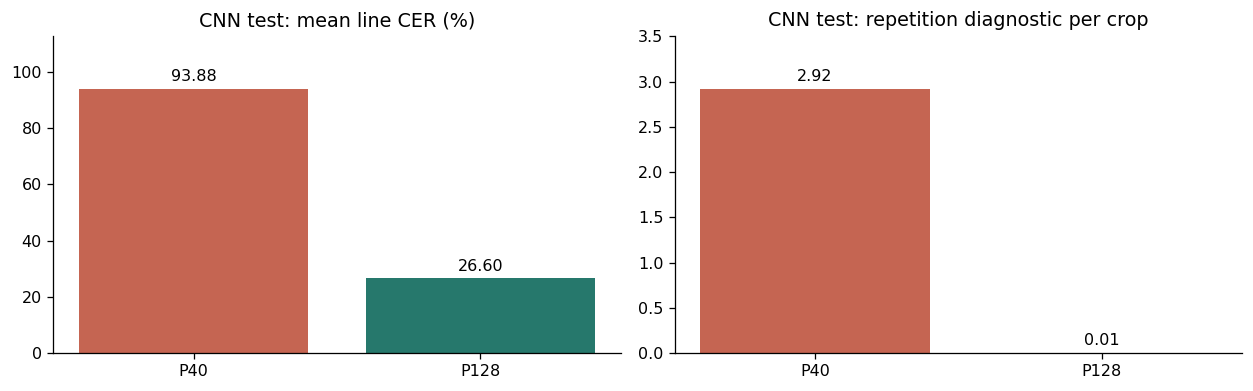

**Selected diagnostic example below:** the largest CER improvement in this pair. It illustrates the failure, not an average or randomly chosen result. Use the browser to inspect unchanged/worse cases too. Repeated-insertion counts are a heuristic, not proof of the exact cause.

CNN test | example 1/174 | filter: All | order: Biggest improvement
File: reader__images__wb__cnn_14_000.png


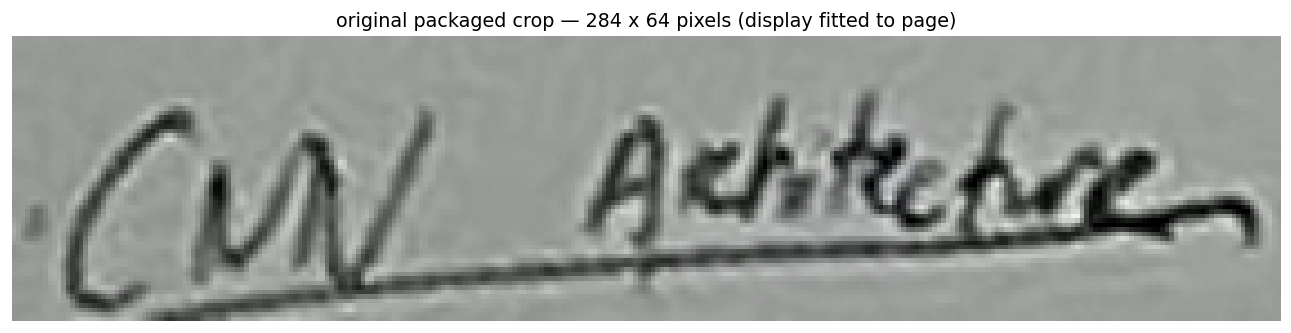

Model,Saved reading,Line CER
P40,- CN Aieh tec chchchchecueeive.,137.5%
,- cn aieh tec chchchchecueeive.,
P128,CNN Achitecture,6.2%
,cnn architecture,


In [6]:
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for ax,metric,title in [(axes[0],'mean_CER','CNN test: mean line CER (%)'),
                         (axes[1],'repeats','CNN test: repetition diagnostic per crop')]:
    vals=[summary.loc[(m,'CNN test'),metric]*(100 if metric=='mean_CER' else 1) for m in ['P40','P128']]
    bars=ax.bar(['P40','P128'],vals,color=['#c56552','#26786c'])
    ax.bar_label(bars,fmt='%.2f',padding=3)
    ax.set(title=title,ylim=(0,max(vals)*1.2))
fig.tight_layout(); plt.show()
display(Markdown('**Selected diagnostic example below:** the largest CER improvement in this pair. '
    'It illustrates the failure, not an average or randomly chosen result. Use the browser to inspect unchanged/worse cases too. '
    'Repeated-insertion counts are a heuristic, not proof of the exact cause.'))
show_pair(before='P40',after='P128',order='Biggest improvement')

## 4b. Original recipe vs our adapted recipe (C1 vs V3)

C1 trains on the **same data as V3** with PaddleOCR's original geometry and pooling (48 x 320, 40 training slots). V3 uses our adapted recipe (64 x 1024, width / 8 slots). Several things change at once (height, width, pooling, which lines fit), so this compares **recipes**, not pooling alone; section 4 is the pooling-only test.

Note that C1 has no train/read mismatch: at 320 wide, both make 40 slots. Its limit is **capacity**: 1,231 of V3's training lines needed more than 40 slots and could not be used.

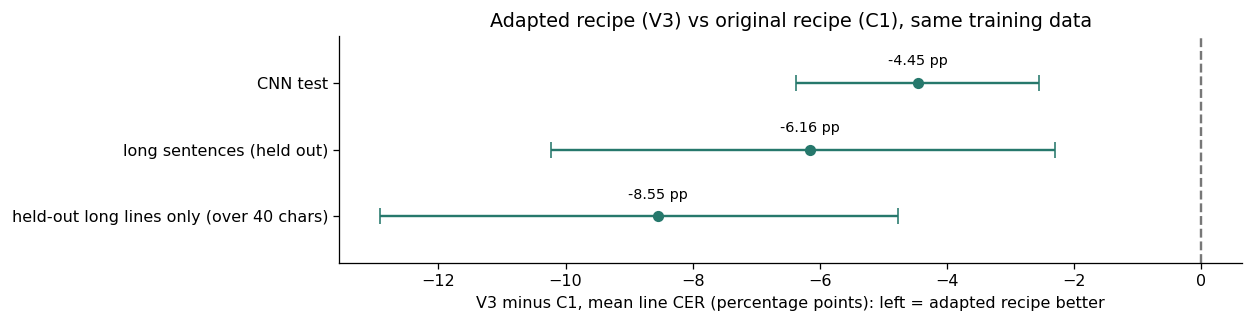

,C1 CER (%),V3 CER (%),Difference (pp),95% interval,Verdict
Set,,,,,
CNN test,28.72,24.27,-4.45,-6.37 .. -2.54,better
long sentences (held out),8.81,2.65,-6.16,-10.23 .. -2.30,better
held-out long lines only (over 40 chars),12.15,3.60,-8.55,-12.92 .. -4.77,better


The gap is largest on the lines over 40 characters, which fits the capacity explanation: C1 could not train on most long lines. One seed; the >40 view is 41 crops of 5 sentences from one writer.

In [7]:
SET_ORDER = ['CNN test', 'long sentences (held out)', 'held-out long lines only (over 40 chars)']
fig, ax = plt.subplots(figsize=(11, 2.9))
rows = []
for y, st in enumerate(SET_ORDER):
    v = saved['comparisons'][f'{st}: V3 vs C1']
    d, lo, hi = [100 * v[k] for k in ['diff', 'lo', 'hi']]
    ax.errorbar(d, y, xerr=[[d - lo], [hi - d]], fmt='o', capsize=5, color='#26786c' if hi < 0 else '#a06d25')
    ax.annotate(f'{d:+.2f} pp', (d, y), xytext=(0, 11), textcoords='offset points', ha='center', fontsize=9)
    rows.append({'Set': st, 'C1 CER (%)': 100 * summary.loc[('C1', st), 'mean_CER'] if ('C1', st) in summary.index else float('nan'),
                 'V3 CER (%)': 100 * summary.loc[('V3', st), 'mean_CER'] if ('V3', st) in summary.index else float('nan'),
                 'Difference (pp)': d, '95% interval': f'{lo:+.2f} .. {hi:+.2f}', 'Verdict': v['verdict']})
ax.axvline(0, color='#777', linestyle='--')
ax.set(yticks=range(len(SET_ORDER)), yticklabels=SET_ORDER, xlabel='V3 minus C1, mean line CER (percentage points): left = adapted recipe better',
       title='Adapted recipe (V3) vs original recipe (C1), same training data')
ax.set_ylim(len(SET_ORDER) - .3, -.7); fig.tight_layout(); plt.show()
LONG_VIEW = 'held-out long lines only (over 40 chars)'
for m in ['C1', 'V3']:
    if (m, LONG_VIEW) not in summary.index:
        part = df[df['set'].eq('long sentences (held out)') & df.model.eq(m) & df.length.eq('over 40 chars')]
        rows[2][f'{m} CER (%)'] = 100 * part.cer.mean()
display(pd.DataFrame(rows).set_index('Set').round(2))
display(Markdown('The gap is largest on the lines over 40 characters, which fits the capacity explanation: '
    'C1 could not train on most long lines. One seed; the >40 view is 41 crops of 5 sentences from one writer.'))

## 4c. The step-by-step ladder: what each change contributes (C0, 11 Nov)

Sections 4 and 4b each compare **one pair**. This section lines the runs up so that **every step changes exactly one thing**. One rung was missing, so **C0** was trained on 11 Nov: V2's crops **without** our augmented copies, with PaddleOCR's **original recipe** (48 × 320 input, 40 positions).

| step | the only change | how we know it is the only change |
|---|---|---|
| pretrained → **C0** | fine-tune on our crops | same model, same reading; C0 adds training on our data |
| C0 → **C1** | + our pre-made augmented copies | C1's 4,269 lines = C0's 1,113 crops + 3,156 copies **of those crops** (checked) |
| C1 → **P40** | input 48 × 320 → 64 × 1024, still 40 positions | C1, P40 and P128 train on one **byte-identical** list |
| P40 → **P128** | training pooling 40 positions → width / 8 | same list, same input (section 4) |
| P128 → **V3** | + the lines that need more than 40 positions | V3 = P128's lines + 1,231 longer ones |

**Fair budget.** Every rung gets about 6,000 updates of 16 crops. C0 does 86 passes (epochs) over its 1,113 crops, C1 does 22 passes over 4,269 lines (each crop ≈ 3.8 times per pass). So both see each piece of handwriting about **85 times**: C0 as itself, C1 mostly as altered copies. C0 → C1 asks one question: *do pre-made altered copies beat repeats of the original?* (Both also get PaddleOCR's built-in random augmentation.)

**Same scorer.** Before training, the C0 script checked that every data list is byte-identical to versions_2x2 and that the pretrained model reads whiteboard validation **100 % identically** to 6 Nov. So C0's numbers can sit next to the older runs. C0 trains only lines that fit 40 positions, like C1, which is why it has 1,113 of V2's 1,423 lines.

**Mean line CER (%) on each rung. Lower is better.**

,what this rung adds,whiteboard val CER (%),CNN test CER (%),long sentences (held out) CER (%),IAM val CER (%)
pretrained,PP-OCRv5_server_rec as downloaded,15.48,45.79,30.93,12.20
C0,"our crops, original recipe (48x320, 40 positions)",8.88,29.00,7.84,30.57
C1,+ our augmented copies,9.30,28.72,8.81,31.40
P40,"+ wider input (64x1024), still 40 positions",54.54,93.88,45.26,60.98
P128,+ width/8 training pooling,6.44,26.60,4.55,21.68
V3,+ lines needing more than 40 positions,7.18,24.27,2.65,25.71


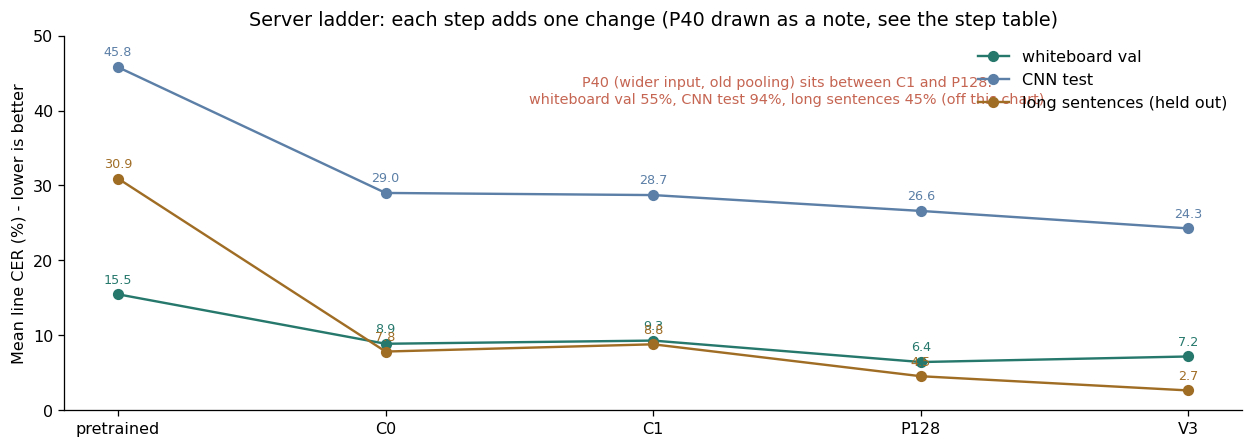

**Each step in percentage points, with the 95% interval.** Negative = the change lowered CER. "better" / "worse" only when the whole interval is on one side of zero.

,change,whiteboard val,CNN test,long sentences (held out),IAM val
step,,,,,
pretrained -> C0,fine-tune on our crops,"-6.60 [-9.71, -3.37] better","-16.79 [-20.13, -13.40] better","-23.09 [-33.52, -10.64] better","+18.38 [+17.57, +19.16] worse"
C0 -> C1,+ augmented copies,"+0.42 [-0.49, +1.46]","-0.28 [-1.16, +0.62]","+0.97 [+0.04, +2.02] worse","+0.83 [+0.36, +1.29] worse"
C1 -> P40,+ wider input only,"+45.24 [+40.08, +48.37] worse","+65.16 [+60.21, +69.86] worse","+36.46 [+28.14, +46.42] worse","+29.58 [+28.43, +30.69] worse"
P40 -> P128,+ width/8 pooling,"-48.10 [-51.00, -43.65] better","-67.27 [-71.80, -62.91] better","-40.72 [-48.68, -33.96] better","-39.30 [-40.45, -38.06] better"
C1 -> P128,wider input + pooling together,"-2.86 [-4.87, -1.65] better","-2.12 [-3.59, -0.71] better","-4.26 [-7.21, -1.77] better","-9.72 [-10.28, -9.14] better"
P128 -> V3,+ long lines,"+0.74 [-0.22, +1.99]","-2.33 [-3.74, -0.86] better","-1.90 [-3.56, -0.29] better","+4.02 [+3.62, +4.42] worse"


C0 on the new-writer test: **42.4%** (160 crops). The older rungs were not scored on this set on the GPU, so it has no ladder; C0 also trained on the 64 teammate crops, whose writers may be the test writers.

In [8]:
C0_DIR = ASSIGNMENT / 'results_server_c0_20261111'
dc0 = pd.read_csv(C0_DIR / 'results/predictions.csv', keep_default_na=False)
c0_saved = json.loads((C0_DIR / 'results/summary.json').read_text())
assert c0_saved['pretrained_identical'] == 1.0, 'C0 was scored with a different reader setup'
LADDER_SETS = ['whiteboard val', 'CNN test', 'long sentences (held out)', 'IAM val']
RUNGS = ['pretrained', 'C0', 'C1', 'P40', 'P128', 'V3']
dl = pd.concat([df[df.model.isin(RUNGS) & df['set'].isin(LADDER_SETS)], dc0[dc0['set'].isin(LADDER_SETS)]], ignore_index=True)
for st in LADDER_SETS:
    sig = {m: set(zip(g.file, g.label, g.cluster)) for m, g in dl[dl['set'].eq(st)].groupby('model')}
    assert len(sig) == len(RUNGS) and all(s == sig['C1'] for s in sig.values()), f'different crops or labels in {st}'

def cluster_bootstrap(a, b, st, n=2000):
    '''A - B on the same crops; 95% interval resampling whole photos (whole sentences for the long set).
    Same method and random seed as the RunPod reports, so the numbers match them.'''
    ra = dl[dl.model.eq(a) & dl['set'].eq(st)]
    B = dict(zip(*[dl[dl.model.eq(b) & dl['set'].eq(st)][k] for k in ('file', 'cer')]))
    groups = defaultdict(list)
    for f, cl, c in zip(ra.file, ra.cluster, ra.cer):
        groups[cl].append(c - B[f])
    g = list(groups.values()); mean = lambda gs: sum(map(sum, gs)) / sum(map(len, gs))
    rng = random.Random(0)
    sims = sorted(mean([g[rng.randrange(len(g))] for _ in g]) for _ in range(n))
    return mean(g), sims[int(0.025 * n)], sims[int(0.975 * n) - 1]

for st in LADDER_SETS:
    d, lo, hi = cluster_bootstrap('C0', 'pretrained', st)
    v = c0_saved['comparisons'][f'{st}: C0 vs pretrained']
    assert max(abs(d - v['diff']), abs(lo - v['lo']), abs(hi - v['hi'])) < 1e-9, 'recalculation differs from the RunPod report'

WHAT = {'pretrained': 'PP-OCRv5_server_rec as downloaded', 'C0': 'our crops, original recipe (48x320, 40 positions)',
        'C1': '+ our augmented copies', 'P40': '+ wider input (64x1024), still 40 positions',
        'P128': '+ width/8 training pooling', 'V3': '+ lines needing more than 40 positions'}
mm = dl.groupby(['model', 'set']).cer.mean() * 100
ladder = pd.DataFrame({st: [mm[(m, st)] for m in RUNGS] for st in LADDER_SETS}, index=RUNGS)
ladder.insert(0, 'what this rung adds', [WHAT[m] for m in RUNGS])
display(Markdown('**Mean line CER (%) on each rung. Lower is better.**'))
display(ladder.rename(columns=lambda c: c if c.startswith('what') else c + ' CER (%)').round(2))

MAIN = ['pretrained', 'C0', 'C1', 'P128', 'V3']
fig, ax = plt.subplots(figsize=(11, 4))
for st, colour in zip(LADDER_SETS[:3], ['#26786c', '#5b7fa6', '#a06d25']):
    vals = [mm[(m, st)] for m in MAIN]
    ax.plot(MAIN, vals, marker='o', color=colour, label=st)
    for x, v in enumerate(vals):
        ax.annotate(f'{v:.1f}', (x, v), xytext=(0, 7), textcoords='offset points', ha='center', fontsize=8, color=colour)
ax.annotate('P40 (wider input, old pooling) sits between C1 and P128:\n'
            + ', '.join(f'{st.split(" (")[0]} {mm[("P40", st)]:.0f}%' for st in LADDER_SETS[:3]) + ' (off this chart)',
            (2.5, 41), ha='center', fontsize=9, color='#c56552')
ax.set(ylabel='Mean line CER (%) - lower is better', ylim=(0, 50),
       title='Server ladder: each step adds one change (P40 drawn as a note, see the step table)')
ax.legend(frameon=False); fig.tight_layout(); plt.show()

STEPS = [('C0', 'pretrained', 'fine-tune on our crops'), ('C1', 'C0', '+ augmented copies'),
         ('P40', 'C1', '+ wider input only'), ('P128', 'P40', '+ width/8 pooling'),
         ('P128', 'C1', 'wider input + pooling together'), ('V3', 'P128', '+ long lines')]
step_rows = []
for a, b, what in STEPS:
    row = {'step': f'{b} -> {a}', 'change': what}
    for st in LADDER_SETS:
        d, lo, hi = cluster_bootstrap(a, b, st)
        row[st] = f'{100 * d:+.2f} [{100 * lo:+.2f}, {100 * hi:+.2f}]' + (' better' if hi < 0 else ' worse' if lo > 0 else '')
    step_rows.append(row)
display(Markdown('**Each step in percentage points, with the 95% interval.** Negative = the change lowered CER. '
                 '"better" / "worse" only when the whole interval is on one side of zero.'))
display(pd.DataFrame(step_rows).set_index('step'))
nw = dc0[dc0['set'].eq('new writers')]
display(Markdown(f'C0 on the new-writer test: **{100 * nw.cer.mean():.1f}%** ({len(nw)} crops). The older rungs were not '
                 'scored on this set on the GPU, so it has no ladder; C0 also trained on the 64 teammate crops, '
                 'whose writers may be the test writers.'))

**One crop read by every rung.** The example is the **longest held-out sentence label** (chosen by length, not by which model looks best), so it shows the capacity limit of the 40-position rungs. Change `LADDER_INDEX` to step through the held-out sentences from longest to shortest.

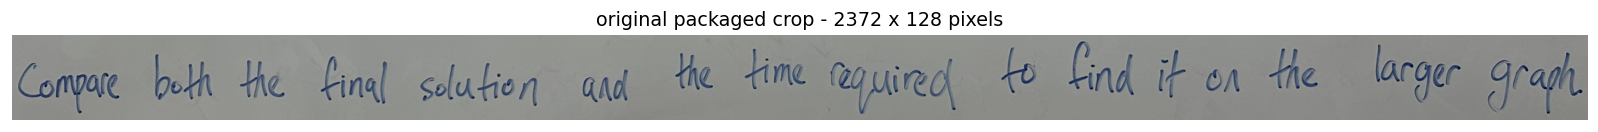

Rung,Reading (red = edit),Line CER
pretrained,compare both the final solution and the time required to find it on the larger graph.,17.6%
C0,compare both the final solution and the time required to find it on the larger graph.,2.4%
C1,compare buth the final solution and the time required to find it on the larger graph.,2.4%
P40,compare both the final so ution ined the ti me remu reod to f ndh zana tihe larger e mphe,25.9%
P128,compare both the final solution and the time required to find it on the larger graph.,1.2%
V3,compare both the final solution and the time required to find it on the larger graph.,0.0%


In [9]:
LADDER_INDEX = 0
held = dl[dl.model.eq('C0') & dl['set'].eq('long sentences (held out)')].copy()
held = held.assign(n=held.label.str.len()).sort_values(['n', 'file'], ascending=[False, True]).reset_index(drop=True)
pick = held.iloc[min(max(LADDER_INDEX, 0), len(held) - 1)]
try:
    im, source = load_crop(pick.file)
    fig, ax = plt.subplots(figsize=(14, 2.6)); ax.imshow(im); ax.axis('off')
    ax.set_title(f'{source} - {im.width} x {im.height} pixels'); fig.tight_layout(); plt.show()
except FileNotFoundError as exc:
    print(exc)
body = f'<p><b>Saved ground truth:</b> {html.escape(pick.label)} ({len(pick.label)} characters)</p>'
body += '<table style="text-align:left;border-collapse:collapse;width:100%"><tr><th>Rung</th><th>Reading (red = edit)</th><th>Line CER</th></tr>'
for m in RUNGS:
    r = dl[dl.model.eq(m) & dl['set'].eq('long sentences (held out)') & dl.file.eq(pick.file)].iloc[0]
    body += (f'<tr><td style="padding:6px">{m}</td><td style="padding:6px;white-space:pre-wrap;font:15px monospace">'
             f'{coloured_reading(r.label, r.pred)}</td><td>{r.cer:.1%}</td></tr>')
display(HTML(body + '</table>'))

**How to read the ladder**

1. **Fine-tuning on our crops is by far the biggest step** (pretrained → C0: about −7 points on validation, −17 on the CNN board, −23 on held-out sentences). The data does most of the work. The price is general handwriting: IAM gets about 18 points worse, because the model specialises in whiteboards.
2. **Pre-made augmented copies add nothing** (C0 → C1: within noise on validation and CNN, slightly worse on held-out sentences). This is the **second recipe** where copies did not help (V2 → V3 in section 6 was the first), so it is a pattern, not one unlucky run. A likely reason: PaddleOCR already augments every crop at random during training.
3. **A wider input on its own breaks the model** (C1 → P40: about +45 points). With 40 training positions over 1,024 pixels, each position covers about 25 px in training but about 8 px when reading (section 4).
4. **The pooling change repairs it** (P40 → P128: about −48 points). Steps 3 and 4 belong together: the combined step **C1 → P128** is the real effect of our adapted recipe on the same lines, about **−3 points on validation, −2 on CNN, −4 on held-out sentences**. Real, but much smaller than the effect of our data.
5. **Adding the long lines** (P128 → V3) helps the CNN board and the held-out sentences by about 2 points; on validation it is within noise.

**Limits:** one seed per rung (seed-to-seed noise on validation was about 1 point in section 7b), so steps under about 2 points are "within noise", not findings. The intervals cover which test crops happen to be in each set, not training randomness. C0 was trained on 11 Nov, the other rungs on 6 Nov, with the same training code and data.

## 5. How did training progress?

These curves come from the **actual validation log entries**. Higher `norm_edit_dis` means a reading closer to the label. It is PaddleOCR's validation similarity metric, not the CER shown above and not exact-line accuracy.

Stars mark the best logged validation value. A falling training loss alone does not prove that recognition on new data improved.

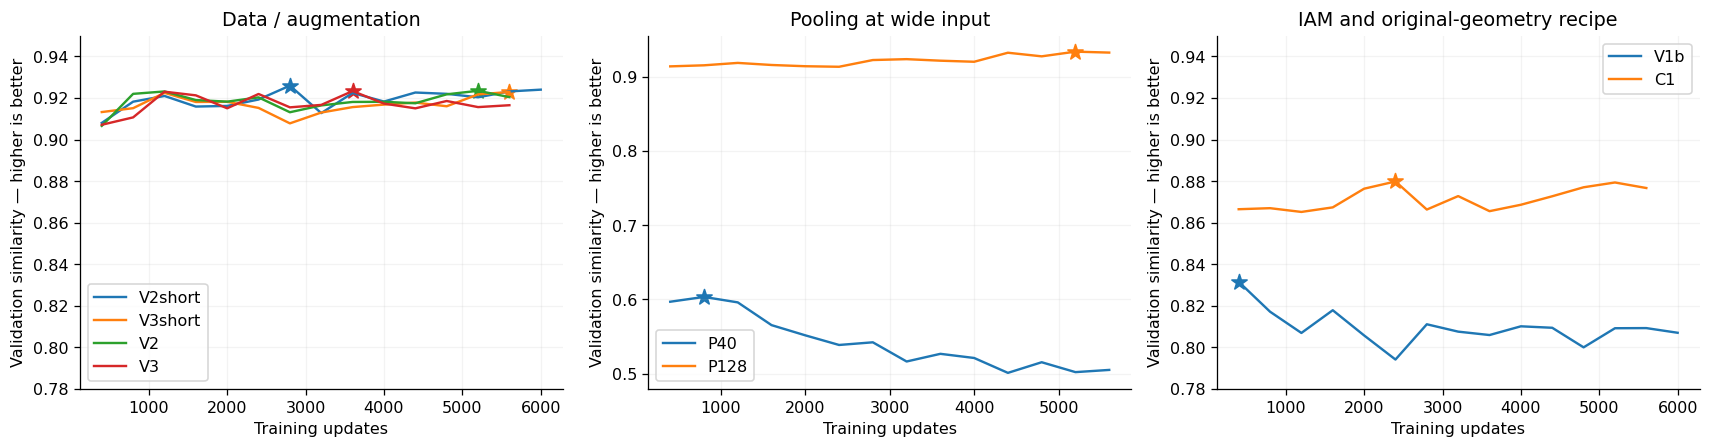

,Best validation update,Best validation similarity
Run,,
V1b,400,0.8316
V2short,2800,0.9259
V3short,5600,0.9229
V2,5200,0.9234
V3,3600,0.9233
C1,2400,0.8798
P40,800,0.6033
P128,5200,0.9335


**Scale note:** the first and third panels share the axis 0.78–0.95. After about 1,200 updates, A–D move within roughly ±0.01. A–D gained much of their validation performance early. Small later changes need repeated seeds before calling them meaningful or merely noise. P128 continued improving later.

In [10]:
histories={}
for model in DESCRIPTIONS:
    events=[]; step=0
    for line in (RESULTS/'runs'/model/'train_log.txt').read_text(errors='replace').splitlines():
        match=re.search(r'global_step: (\d+)',line)
        if match: step=int(match.group(1))
        if 'cur metric,' in line:
            value=re.search(r'norm_edit_dis: ([\d.eE+-]+)',line)
            if value: events.append((step,float(value.group(1))))
    assert events, f'No validation entries for {model}'
    histories[model]=pd.DataFrame(events,columns=['update','validation_similarity'])

fig,axes=plt.subplots(1,3,figsize=(15,4))
panels=[(['V2short','V3short','V2','V3'],'Data / augmentation'),
        (['P40','P128'],'Pooling at wide input'),(['V1b','C1'],'IAM and original-geometry recipe')]
for ax,(models,title) in zip(axes,panels):
    for model in models:
        h=histories[model]; line,=ax.plot(h['update'],h.validation_similarity,label=model)
        best=h.loc[h.validation_similarity.idxmax()]
        ax.scatter(best['update'],best.validation_similarity,marker='*',s=100,color=line.get_color())
    ax.set(title=title,xlabel='Training updates',ylabel='Validation similarity — higher is better')
    if title != 'Pooling at wide input':
        ax.set_ylim(0.78, 0.95)   # same scale for both panels; the A-D wiggles are small
    ax.legend(); ax.grid(alpha=.15)
fig.tight_layout();plt.show()
display(pd.DataFrame([{'Run':m,'Best validation update':int(h.loc[h.validation_similarity.idxmax(),'update']),
    'Best validation similarity':h.validation_similarity.max()} for m,h in histories.items()]).set_index('Run').round(4))
display(Markdown('**Scale note:** the first and third panels share the axis 0.78–0.95. After about 1,200 updates, A–D move within roughly ±0.01. '
    'A–D gained much of their validation performance early. Small later changes need repeated seeds '
    'before calling them meaningful or merely noise. P128 continued improving later.'))

## 6. Did long lines and extra augmentation help?

**Important: the CNN test has no lines over 40 characters** (see the counts below). It can show whether the recipes generalise, but it cannot show whether long-line training helps **long lines**. That evidence comes from the **held-out long sentences** and their subset of lines over 40 characters.

The plots use the saved **photo-cluster bootstrap intervals** (whole sentences for the held-out set). Negative means the named change reduced CER. An interval crossing zero means **no clear difference in this comparison**.

These intervals describe this evaluation material. They do not include uncertainty from training seeds or new writers. Adding long lines also increased the amount of data (~28% more original lines) and changed sampling; it is not a pure line-length intervention. A gain concentrated on long test lines points more specifically to line length.

**Added after the two-seed runs (7 Nov):** these 2×2 runs used one seed each. Later, the same recipe trained with two different seeds (S0 vs S0s2, section 7b) differed by 2.6 points on the CNN test. So the short-only augmentation gain (−2.7 points on CNN) is a single-seed observation that needs replication, not an established effect. The long-line gain on held-out lines over 40 characters is far larger than the seed spread seen there.

**Crops per label length in each whiteboard set:**

length,1-20 chars,21-40 chars,over 40 chars
set,,,
CNN test,57,117,0
long sentences (held out),0,16,41
whiteboard val,86,42,8


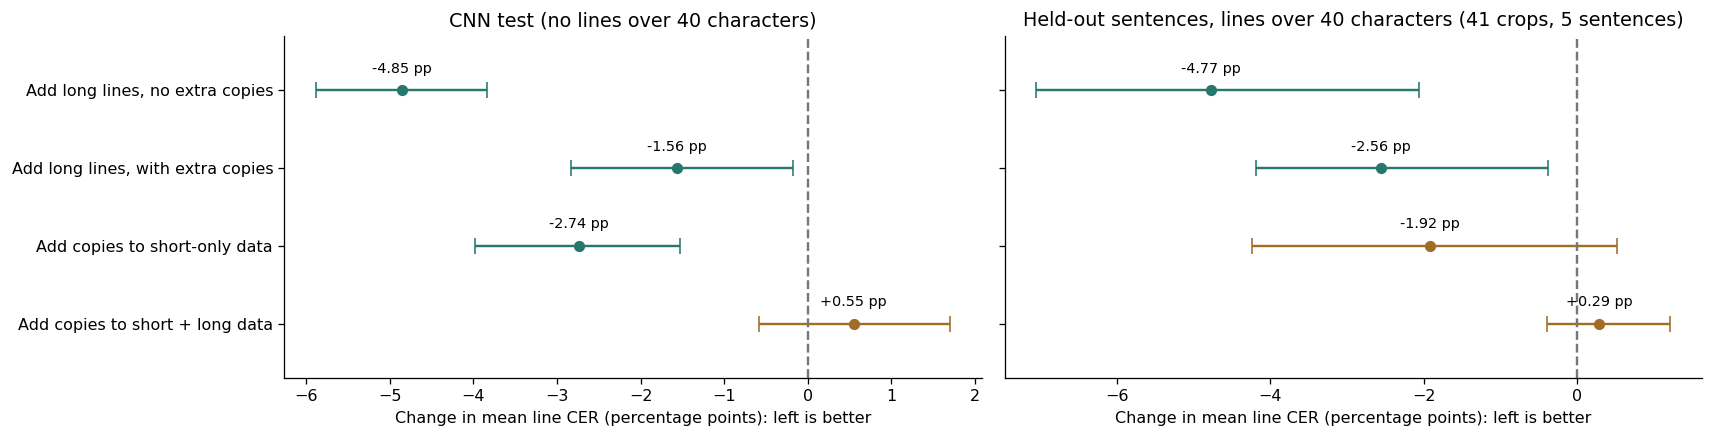

**Held-out sentences, mean line CER (%) by label length** (A = V2short, B = V3short, C = V2, D = V3):

model,V2short,V3short,V2,V3
length,,,,
21-40 chars,0.00,0.22,0.00,0.22
over 40 chars,8.08,6.16,3.31,3.60


**Interaction:** does adding our copies help more (negative) or less (positive) when long lines are included?

,"(D-C)-(B-A), pp",95% interval,Verdict
Set,,,
CNN test,3.29,+1.81 .. +4.86,copies help less with long data
long sentences (held out),1.59,-0.09 .. +3.46,no clear interaction
held-out long lines only (over 40 chars),2.21,-0.01 .. +4.57,no clear interaction


**Observed:** long-inclusive recipes did better in these runs, and the gain is clearest on held-out lines over 40 characters (where A and B, trained only on lines of 40 characters or fewer, had never seen a line that long). Extra copies helped the short-only recipe; their additional benefit with long data was unclear. All recipes already used RecAug. **This does not mean augmentation is universally useless.**

In [11]:
comparisons=[('V2 vs V2short','Add long lines, no extra copies'),
             ('V3 vs V3short','Add long lines, with extra copies'),
             ('V3short vs V2short','Add copies to short-only data'),
             ('V3 vs V2','Add copies to short + long data')]
counts=(df[df.model.eq('V2') & df['set'].isin(['CNN test','long sentences (held out)','whiteboard val'])]
        .pivot_table(index='set',columns='length',values='file',aggfunc='count',fill_value=0))
display(Markdown('**Crops per label length in each whiteboard set:**')); display(counts)

panels=[('CNN test','CNN test (no lines over 40 characters)'),
        ('held-out long lines only (over 40 chars)','Held-out sentences, lines over 40 characters (41 crops, 5 sentences)')]
fig,axes=plt.subplots(1,2,figsize=(15,3.9),sharey=True)
for ax,(st,ptitle) in zip(axes,panels):
  for y,(key,label) in enumerate(comparisons):
    v=saved['comparisons'][st+': '+key]
    d,lo,hi=[100*v[k] for k in ['diff','lo','hi']]
    ax.errorbar(d,y,xerr=[[d-lo],[hi-d]],fmt='o',capsize=5,
        color='#26786c' if hi<0 else '#a06d25')
    ax.annotate(f'{d:+.2f} pp', (d,y),xytext=(0,11),textcoords='offset points',ha='center',fontsize=9)
  ax.axvline(0,color='#777',linestyle='--')
  ax.set(yticks=range(4),yticklabels=[x[1] for x in comparisons],
         xlabel='Change in mean line CER (percentage points): left is better',title=ptitle)
  ax.set_ylim(3.7,-.7)
fig.tight_layout();plt.show()

by_len=(df[df.model.isin(['V2short','V3short','V2','V3']) & df['set'].eq('long sentences (held out)')]
        .pivot_table(index='length',columns='model',values='cer',aggfunc='mean')[['V2short','V3short','V2','V3']]*100)
display(Markdown('**Held-out sentences, mean line CER (%) by label length** (A = V2short, B = V3short, C = V2, D = V3):'))
display(by_len.round(2))

inter=[]
for st in ['CNN test','long sentences (held out)','held-out long lines only (over 40 chars)']:
    v=saved['comparisons'].get('interaction '+st)
    if v: inter.append({'Set':st,'(D-C)-(B-A), pp':100*v['diff'],'95% interval':f"{100*v['lo']:+.2f} .. {100*v['hi']:+.2f}",'Verdict':v['verdict']})
display(Markdown('**Interaction:** does adding our copies help more (negative) or less (positive) when long lines are included?'))
display(pd.DataFrame(inter).set_index('Set').round(2))
display(Markdown('**Observed:** long-inclusive recipes did better in these runs, and the gain is clearest on held-out lines over 40 characters (where A and B, trained only on lines of 40 characters or fewer, had never seen a line that long). Extra copies helped the short-only recipe; '
    'their additional benefit with long data was unclear. All recipes already used RecAug. '
    '**This does not mean augmentation is universally useless.**'))

## 6b. What happened to general handwriting (IAM)?

IAM validation is printed handwriting from many writers on paper, not whiteboards. It measures how much **general** handwriting reading is kept after fine-tuning on whiteboards. Every run started from the same pretrained model, so the fair reference is **pretrained**, not V1b (V1b is a separate model fine-tuned on IAM itself).

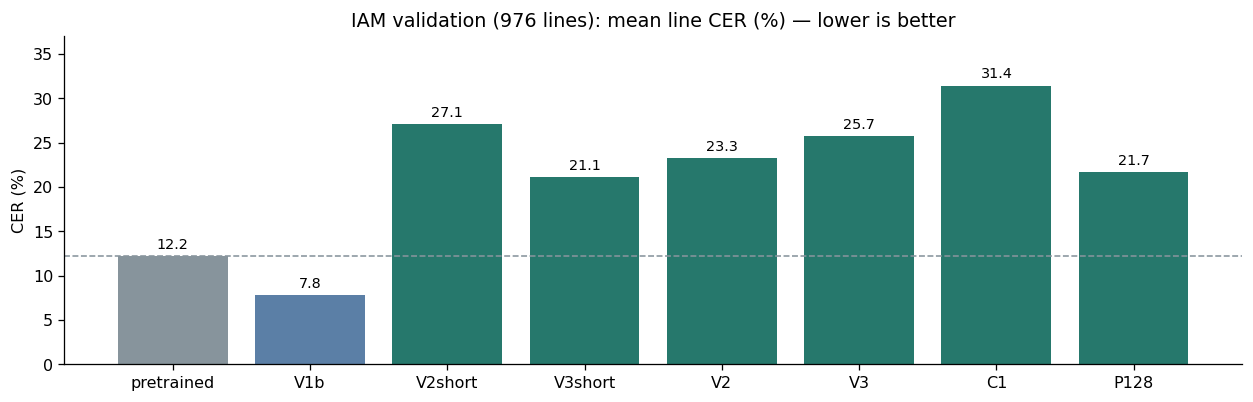

**Reading:** whiteboard fine-tuning made IAM worse: pretrained 12.2% → V2 23.3% (1.9x the error). The models specialised to our boards and lost some general handwriting ability. This is the motivation for **S1 (layer-wise learning rates)** in section 9: smaller learning rates for the early backbone layers may protect the general stroke features. That is a hypothesis to test, not a guaranteed effect. P40 is left out of this chart (61.0%) because it fails everywhere.

In [12]:
iam_models=[m for m in ['pretrained','V1b','V2short','V3short','V2','V3','C1','P128'] if (m,'IAM val') in summary.index]
vals=[100*summary.loc[(m,'IAM val'),'mean_CER'] for m in iam_models]
fig,ax=plt.subplots(figsize=(11,3.6))
bars=ax.bar(iam_models,vals,color=['#87949c' if m=='pretrained' else '#5b7fa6' if m=='V1b' else '#26786c' for m in iam_models])
ax.bar_label(bars,fmt='%.1f',padding=3,fontsize=9)
ax.axhline(vals[0],color='#87949c',linestyle='--',linewidth=1)
ax.set(title='IAM validation (976 lines): mean line CER (%) — lower is better',ylabel='CER (%)',ylim=(0,max(vals)*1.18))
fig.tight_layout();plt.show()
p=summary.loc[('pretrained','IAM val'),'mean_CER']; v2=summary.loc[('V2','IAM val'),'mean_CER']
display(Markdown(f'**Reading:** whiteboard fine-tuning made IAM worse: pretrained {100*p:.1f}% → V2 {100*v2:.1f}% '
    f'({v2/p:.1f}x the error). The models specialised to our boards and lost some general handwriting ability. '
    'This is the motivation for **S1 (layer-wise learning rates)** in section 9: smaller learning rates for the early backbone layers '
    'may protect the general stroke features. That is a hypothesis to test, not a guaranteed effect. P40 is left out of this chart (61.0%) because it fails everywhere.'))

## 7. CTC positions: a small exercise

CTC learns a text sequence without character-location annotations. Each position predicts character probabilities, including a **blank**. Decoding collapses consecutive repeated predictions, then removes blanks.

`H H E L blank L O O` → `H E L blank L O` → **HELLO**.

The blank separates the two Ls. Without it, consecutive Ls would collapse into one L. The minimum CTC positions are the label length **plus one separator for every adjacent repeated character**. More available positions allow repeated predictions and blanks; they do not guarantee correct reading.

This section is a teaching illustration, **not a feature visualisation or a fresh model prediction**.

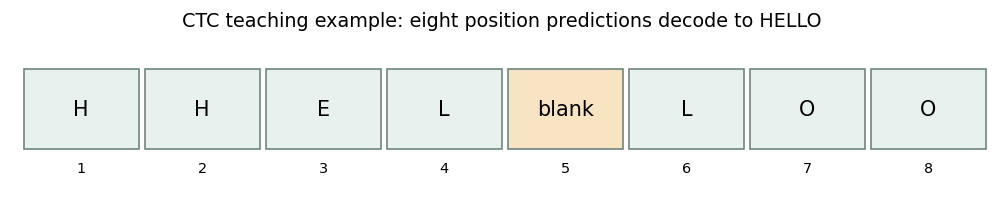

Decoded: HELLO


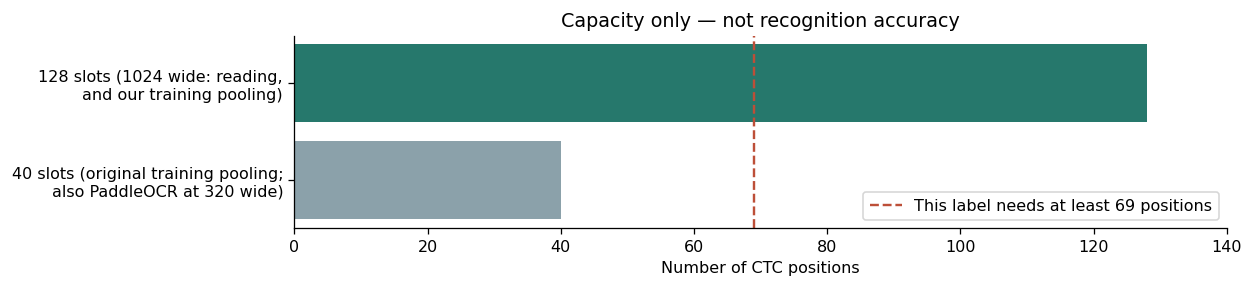

**Your label:** The robot should stop safely when an obstacle blocks the route ahead.  
**Characters:** 69 · **Adjacent repeats:** 0 · **Minimum positions:** 69  
**40:** cannot fit · **128:** can fit. Spaces count as characters. Fitting only means a valid CTC alignment is possible. **This is about capacity, which limits C1 and the 40-slot recipe.** It does not explain P40: P40 trained only on lines that fit in 40 slots; its problem is the 40-vs-128 train/read mismatch in section 4.

In [13]:
def ctc_decode(tokens, blank='<blank>'):
    collapsed=[t for i,t in enumerate(tokens) if i==0 or t!=tokens[i-1]]
    return ''.join(t for t in collapsed if t!=blank)

tokens=['H','H','E','L','<blank>','L','O','O']
assert ctc_decode(tokens)=='HELLO'
fig,ax=plt.subplots(figsize=(11,1.8))
for i,t in enumerate(tokens):
    ax.add_patch(plt.Rectangle((i,0),.95,.7,facecolor='#e7f1ed' if t!='<blank>' else '#f8e4c3',edgecolor='#688279'))
    ax.text(i+.475,.35,t if t!='<blank>' else 'blank',ha='center',va='center',fontsize=13)
    ax.text(i+.475,-.2,str(i+1),ha='center',fontsize=9)
ax.set(xlim=(-.1,len(tokens)),ylim=(-.4,1));ax.axis('off')
ax.set_title('CTC teaching example: eight position predictions decode to HELLO')
plt.show()
print('Decoded:',ctc_decode(tokens))

# Edit this sentence and rerun to see whether the answer CAN fit.
TEXT = 'The robot should stop safely when an obstacle blocks the route ahead.'
needed=len(TEXT)+sum(a==b for a,b in zip(TEXT,TEXT[1:]))
fig,ax=plt.subplots(figsize=(11,2.6))
ax.barh(['40 slots (original training pooling;\nalso PaddleOCR at 320 wide)','128 slots (1024 wide: reading,\nand our training pooling)'],[40,128],color=['#8ba1aa','#26786c'])
ax.axvline(needed,color='#bd4f38',linestyle='--',label=f'This label needs at least {needed} positions')
ax.set(xlim=(0,max(140,needed+10)),xlabel='Number of CTC positions',title='Capacity only — not recognition accuracy')
ax.legend(loc='lower right');fig.tight_layout();plt.show()
display(Markdown(f'**Your label:** {html.escape(TEXT)}  \n**Characters:** {len(TEXT)} · **Adjacent repeats:** {needed-len(TEXT)} · **Minimum positions:** {needed}  \n**40:** {"can fit" if needed<=40 else "cannot fit"} · **128:** {"can fit" if needed<=128 else "cannot fit"}. '
    'Spaces count as characters. Fitting only means a valid CTC alignment is possible. '
    '**This is about capacity, which limits C1 and the 40-slot recipe.** It does not explain P40: P40 trained only on lines that fit in 40 slots; '
    'its problem is the 40-vs-128 train/read mismatch in section 4.'))

## 7b. Can a training strategy help? (S0–S3 and G0, 7 Nov)

Every run below trains on the **same 1,359 lines** (V2's data **minus the 64 teammates' crops**, so the new-writer test is clean), starts from the **pretrained** weights, uses our 64×1024 / width÷8 recipe, and gets exactly **6,035 updates**. Each setting was trained with **two seeds**.

| run | what changes from S0 | idea |
|---|---|---|
| **S0** | nothing (baseline) | |
| **S1** | layer-wise learning rates: backbone layers ×0.1, 0.1, 0.25, 0.5, 1.0 | protect the pretrained low-level features |
| **S2** | focal CTC (easy lines get less weight) | focus on hard lines |
| **S3** | S1 + S2 | do they add up? |
| **G0** | `use_guide: False`: the CTC loss also trains the backbone | let the reader used in the app shape the features |

**How PP-OCRv5 trains (why G0 matters).** During training the model has two heads: the CTC head (the only one used when reading) and an NRTR attention head (training only). With the default `use_guide: True`, the CTC branch's SVTR neck detaches the backbone features, so:

| part | trained by (default) | trained by (G0) |
|---|---|---|
| backbone | NRTR loss only | NRTR **and CTC** loss |
| SVTR neck + CTC head | CTC loss | CTC loss |
| NRTR head | NRTR loss | NRTR loss |

**Decision rule, fixed before training:** whiteboard-validation mean line CER, averaged over both seeds. A setting *helps* only if the 95% interval is below 0 **and** both seeds improve; otherwise "improvement not established" (which is not proof of no effect). Other sets are for reporting. The new-writer set was already looked at while planning G0, so G0's new-writer result is **exploratory**.

same crops and labels in both experiments; pretrained and V1 read identically in both


**Mean line CER (%), averaged over the two seeds** (lower is better):

set,whiteboard val,CNN test,new writers,IAM val
setting,,,,
S0,7.52,25.50,26.79,23.89
S1,7.09,24.58,24.93,23.72
S2,7.24,24.87,26.47,26.53
S3,7.19,25.03,25.97,23.89
G0,7.17,25.70,22.77,27.15
pretrained,15.48,45.79,43.08,12.20


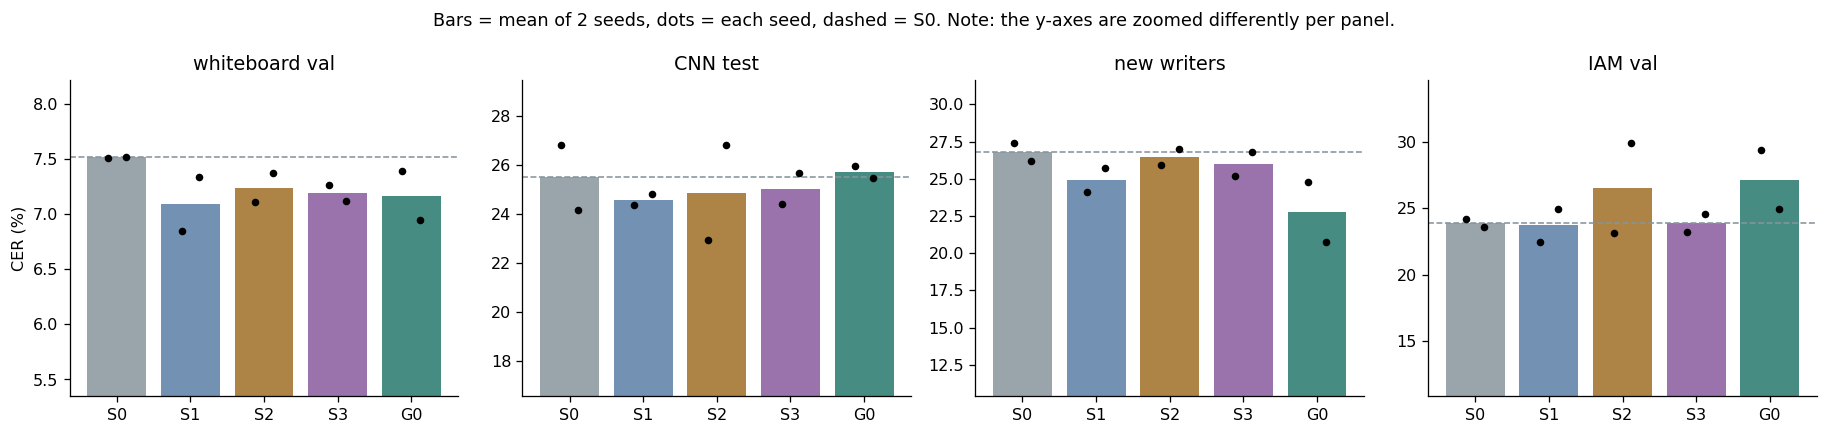

In [14]:
STRAT = ASSIGNMENT / 'results_strategies_s0s3'
GUIDE = ASSIGNMENT / 'results_guide_g0'
MERGED = ASSIGNMENT / 'results_guide_vs_s0'
ds = pd.read_csv(STRAT / 'results/predictions.csv', keep_default_na=False)
dg = pd.read_csv(GUIDE / 'results/predictions.csv', keep_default_na=False)
d2 = pd.concat([ds[ds.model.isin(['pretrained', 'V1', 'S0', 'S0s2', 'S1', 'S1s2', 'S2', 'S2s2', 'S3', 'S3s2'])],
                dg[dg.model.isin(['G0', 'G0s2'])]], ignore_index=True)
# the two experiments must score the same crops with the same labels, and read pretrained/V1 identically
for st in d2['set'].unique():
    sig = {m: set(zip(g.file, g.label)) for m, g in d2[d2['set'].eq(st)].groupby('model')}
    assert all(v == sig['S0'] for v in sig.values()), f'different crops in {st}'
for m in ['pretrained', 'V1']:
    a = ds[ds.model.eq(m)].set_index(['set', 'file']).pred; b = dg[dg.model.eq(m)].set_index(['set', 'file']).pred
    assert (a.sort_index() == b.sort_index()).all(), f'{m} readings differ between experiments'
print('same crops and labels in both experiments; pretrained and V1 read identically in both')

SETS2 = ['whiteboard val', 'CNN test', 'new writers', 'IAM val']
BASES = ['S0', 'S1', 'S2', 'S3', 'G0']
m2 = d2.groupby(['model', 'set']).cer.mean()
rows = []
for b in BASES:
    for st in SETS2:
        rows.append({'setting': b, 'set': st, 'seed 1': 100 * m2[(b, st)], 'seed 2': 100 * m2[(b + 's2', st)]})
tab = pd.DataFrame(rows); tab['mean'] = (tab['seed 1'] + tab['seed 2']) / 2
wide = tab.pivot(index='setting', columns='set', values='mean')[SETS2].loc[BASES]
wide.loc['pretrained'] = [100 * m2[('pretrained', st)] for st in SETS2]
display(Markdown('**Mean line CER (%), averaged over the two seeds** (lower is better):'))
display(wide.round(2))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
cols = {'S0': '#87949c', 'S1': '#5b7fa6', 'S2': '#a06d25', 'S3': '#8a5a9e', 'G0': '#26786c'}
for ax, st in zip(axes, SETS2):
    t = tab[tab['set'].eq(st)].set_index('setting').loc[BASES]
    ax.bar(BASES, t['mean'], color=[cols[b] for b in BASES], alpha=.85)
    for i, b in enumerate(BASES):
        ax.scatter([i - .12, i + .12], [t.loc[b, 'seed 1'], t.loc[b, 'seed 2']], color='black', s=14, zorder=3)
    ax.axhline(t.loc['S0', 'mean'], color='#87949c', linestyle='--', linewidth=1)
    lo = min(t[['seed 1', 'seed 2']].min()) ; hi = max(t[['seed 1', 'seed 2']].max())
    ax.set(title=st, ylim=(max(0, lo - (hi - lo) * 1.5 - .5), hi + (hi - lo) * .6 + .3))
    ax.set_ylabel('CER (%)' if st == SETS2[0] else '')
fig.suptitle('Bars = mean of 2 seeds, dots = each seed, dashed = S0. Note: the y-axes are zoomed differently per panel.', fontsize=11)
fig.tight_layout(); plt.show()

### The pre-declared decision (whiteboard validation, mean of 2 seeds)

In [15]:
sv = json.loads((STRAT / 'results/summary.json').read_text())['comparisons']
gv = json.loads((MERGED / 'summary.json').read_text())['comparisons']
prim = []
for t, v, src in [('S1', sv['primary S1'], sv), ('S2', sv['primary S2'], sv), ('S3', sv['primary S3'], sv), ('G0', gv['primary G0'], gv)]:
    s1 = src[f'whiteboard val: {t} vs S0']['diff']; s2 = src[f'whiteboard val: {t}s2 vs S0s2']['diff']
    prim.append({'setting': t, 'seed 1 vs S0 (pp)': 100 * s1, 'seed 2 vs S0s2 (pp)': 100 * s2,
                 'mean (pp)': 100 * v['diff'], '95% interval (pp)': f"{100*v['lo']:+.2f} .. {100*v['hi']:+.2f}",
                 'decision': 'helps' if v['verdict'] == 'helps' else 'improvement not established'})
display(pd.DataFrame(prim).set_index('setting').round(2))
nwk = [('S1', sv), ('S2', sv), ('S3', sv), ('G0', gv)]
nw = [{'setting': t, 'new writers, mean of seeds vs S0 (pp)': 100 * s[f'new writers: {t}avg vs S0avg']['diff'],
       '95% interval (pp)': f"{100*s[f'new writers: {t}avg vs S0avg']['lo']:+.2f} .. {100*s[f'new writers: {t}avg vs S0avg']['hi']:+.2f}",
       'seed 1 (pp)': 100 * s[f'new writers: {t} vs S0']['diff'], 'seed 2 (pp)': 100 * s[f'new writers: {t}s2 vs S0s2']['diff'],
       'IAM, mean of seeds (pp)': 100 * s[f'IAM val: {t}avg vs S0avg']['diff']} for t, s in nwk]
display(Markdown('**New writers (exploratory) and IAM (out-of-domain check), change vs S0:**'))
display(pd.DataFrame(nw).set_index('setting').round(2))
display(Markdown('**Reading:** no setting met the pre-declared rule on whiteboard validation; all four point the right way '
    'by under half a point. On the two unseen writers, **G0 is the clearest change: about −4 points, in both seeds**, '
    'and S1 about −2. G0 also makes paper handwriting (IAM) worse: the model becomes more specialised to whiteboards. '
    'Focal CTC (S2) depended on the seed. Treat the new-writer gains as a lead to confirm on fresh writers, not a proven result.'))

,seed 1 vs S0 (pp),seed 2 vs S0s2 (pp),mean (pp),95% interval (pp),decision
setting,,,,,
S1,-0.66,-0.18,-0.42,-0.85 .. +0.12,improvement not established
S2,-0.40,-0.14,-0.27,-0.78 .. +0.26,improvement not established
S3,-0.25,-0.40,-0.32,-0.82 .. +0.45,improvement not established
G0,-0.12,-0.57,-0.35,-0.77 .. +0.22,improvement not established


**New writers (exploratory) and IAM (out-of-domain check), change vs S0:**

,"new writers, mean of seeds vs S0 (pp)",95% interval (pp),seed 1 (pp),seed 2 (pp),"IAM, mean of seeds (pp)"
setting,,,,,
S1,-1.86,-3.39 .. -0.75,-3.26,-0.46,-0.16
S2,-0.32,-1.45 .. +0.65,-1.47,0.83,2.65
S3,-0.82,-2.45 .. +0.29,-2.23,0.59,0.01
G0,-4.01,-5.69 .. -2.86,-2.62,-5.41,3.26


**Reading:** no setting met the pre-declared rule on whiteboard validation; all four point the right way by under half a point. On the two unseen writers, **G0 is the clearest change: about −4 points, in both seeds**, and S1 about −2. G0 also makes paper handwriting (IAM) worse: the model becomes more specialised to whiteboards. Focal CTC (S2) depended on the seed. Treat the new-writer gains as a lead to confirm on fresh writers, not a proven result.

### How much does a single training run vary? (seed noise)

S0 and S0s2 are the **same recipe** with a different seed. Their difference shows how much a result can move from training randomness alone, per test set. The report's 95% intervals only cover which test crops happen to be in the set, not this.

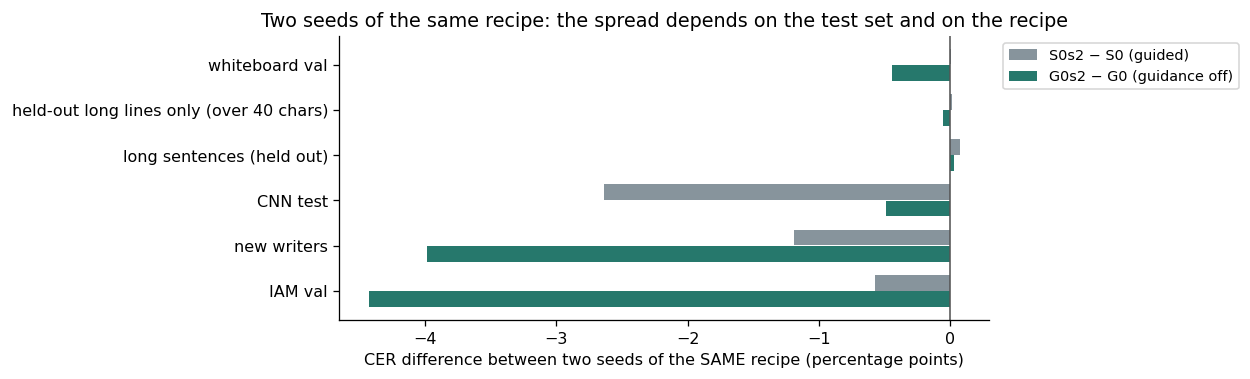

,S0s2 − S0,G0s2 − G0
whiteboard val,0.01,-0.44
held-out long lines only (over 40 chars),0.01,-0.06
long sentences (held out),0.07,0.03
CNN test,-2.64,-0.49
new writers,-1.19,-3.98
IAM val,-0.57,-4.43


**Why this matters:** for the guided recipe, two seeds differ by about 2.6 points on CNN and 1.2 on new writers; for guidance off, by about 4 points on new writers and IAM. One seed alone cannot separate changes of that size from training randomness. That is why S0–S3 and G0 used two seeds, and why single-seed results from the 2×2 batch that are this small (e.g. augmentation, short-only) need replication.

In [16]:
SETS3 = ['whiteboard val', 'held-out long lines only (over 40 chars)', 'long sentences (held out)', 'CNN test', 'new writers', 'IAM val']
d2v = d2.copy()
lv = d2v[d2v['set'].eq('long sentences (held out)') & d2v.length.eq('over 40 chars')].assign(set='held-out long lines only (over 40 chars)')
d2v = pd.concat([d2v, lv]); mm = d2v.groupby(['model', 'set']).cer.mean()
noise = pd.DataFrame({'S0s2 − S0': [100 * (mm[('S0s2', s)] - mm[('S0', s)]) for s in SETS3],
                      'G0s2 − G0': [100 * (mm[('G0s2', s)] - mm[('G0', s)]) for s in SETS3]}, index=SETS3)
fig, ax = plt.subplots(figsize=(11, 3.4))
y = np.arange(len(SETS3))
ax.barh(y - .18, noise['S0s2 − S0'], height=.35, color='#87949c', label='S0s2 − S0 (guided)')
ax.barh(y + .18, noise['G0s2 − G0'], height=.35, color='#26786c', label='G0s2 − G0 (guidance off)')
ax.axvline(0, color='#555', linewidth=1)
ax.set(yticks=y, yticklabels=SETS3, xlabel='CER difference between two seeds of the SAME recipe (percentage points)',
       title='Two seeds of the same recipe: the spread depends on the test set and on the recipe')
ax.invert_yaxis(); ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9); fig.tight_layout(); plt.show()
display(noise.round(2))
display(Markdown('**Why this matters:** for the guided recipe, two seeds differ by about 2.6 points on CNN and 1.2 on new writers; '
    'for guidance off, by about 4 points on new writers and IAM. One seed '
    'alone cannot separate changes of that size from training randomness. That is why S0–S3 and G0 used two seeds, and why '
    'single-seed results from the 2×2 batch that are this small (e.g. augmentation, short-only) need replication.'))

### New writers: by writer and by line length

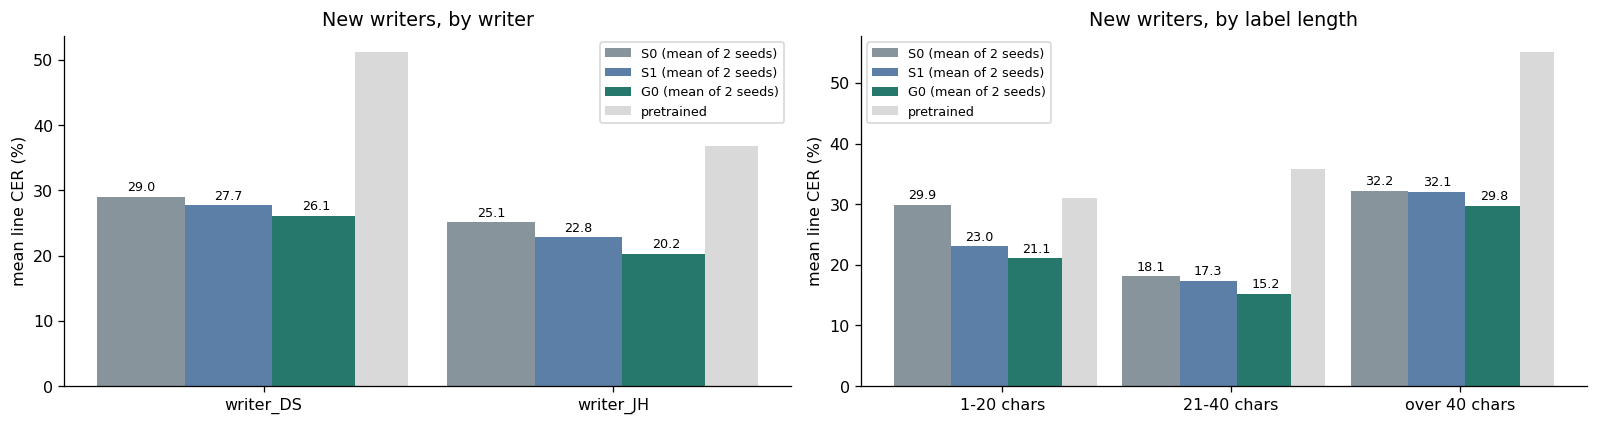

G0 is better than S0 for **both** writers and at **every** line length, in the mean of two seeds. Only two writers: this is a first look at generalisation, not an estimate for all handwriting.

In [17]:
nwr = d2[d2['set'].eq('new writers')].assign(writer=lambda x: x.cluster.str.split(':').str[0])
pw = nwr.groupby(['model', 'writer']).cer.mean().unstack() * 100
pl = nwr.groupby(['model', 'length']).cer.mean().unstack()[['1-20 chars', '21-40 chars', 'over 40 chars']] * 100
avg = lambda t, b: (t.loc[b] + t.loc[b + 's2']) / 2
showm = ['S0', 'S1', 'G0']
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, t, title in [(axes[0], pw, 'by writer'), (axes[1], pl, 'by label length')]:
    cats = list(t.columns); x = np.arange(len(cats)); w = .25
    for k, b in enumerate(showm):
        v = avg(t, b)
        bars = ax.bar(x + (k - 1) * w, v, width=w, color=cols[b], label=f'{b} (mean of 2 seeds)')
        ax.bar_label(bars, fmt='%.1f', fontsize=8, padding=2)
    ax.bar(x + 1.75 * w, t.loc['pretrained'], width=w * .6, color='#d9d9d9', label='pretrained')
    ax.set(xticks=x + .1, xticklabels=cats, ylabel='mean line CER (%)', title=f'New writers, {title}')
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
display(Markdown('G0 is better than S0 for **both** writers and at **every** line length, in the mean of two seeds. '
    'Only two writers: this is a first look at generalisation, not an estimate for all handwriting.'))

### Look at the crops: S0 vs G0 on the new writers

Same crop, same label, two readings. The first examples are the **biggest improvements**, then the **biggest regressions** (seed 1 pair: S0 → G0). Change `index` or `order` to look further. Looking at these errors for choosing *further* changes makes the new-writer set development data; a later claim about unseen writers then needs fresh writers.

new writers | S0 -> G0 | Biggest improvement #1 of 160 | writer_JH:jhw:JH26 | newwriter__images__jhw__train__JH26.1.jpg


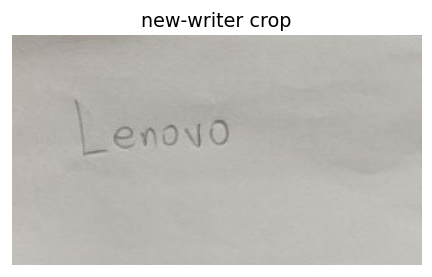

S0,l.enouns,66.7%
G0,lenovo,0.0%


new writers | S0 -> G0 | Biggest improvement #2 of 160 | writer_JH:jhw:JH17 | newwriter__images__jhw__train__JH17.3.jpg


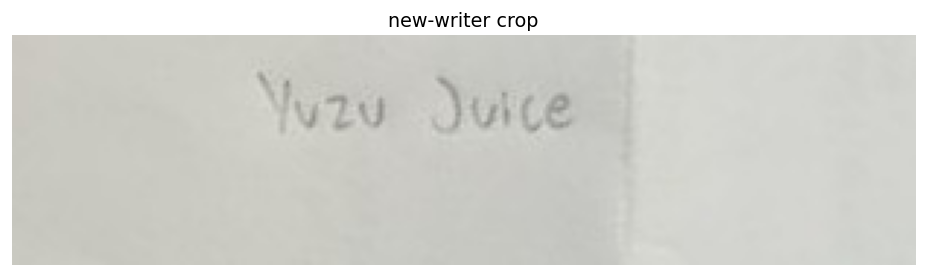

S0,puizin suice,60.0%
G0,vuzu duice,20.0%


new writers | S0 -> G0 | Biggest improvement #3 of 160 | writer_JH:jhw:JH21 | newwriter__images__jhw__train__JH21.1.jpg


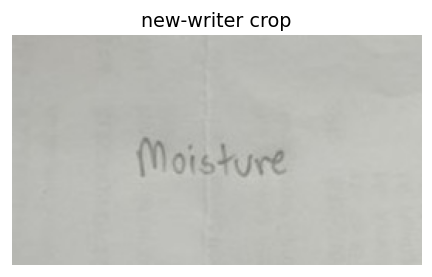

S0,moisturn,37.5%
G0,moisture,0.0%


new writers | S0 -> G0 | Biggest regression #1 of 160 | writer_JH:jhw:JH33 | newwriter__images__jhw__train__JH33.1.jpg


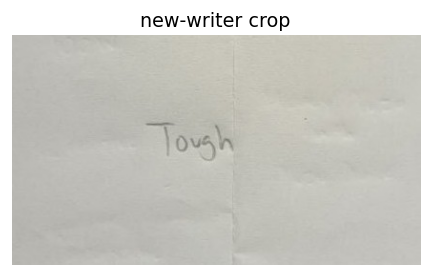

S0,tougs,60.0%
G0,tough,100.0%


new writers | S0 -> G0 | Biggest regression #2 of 160 | writer_JH:jhw:JH7 | newwriter__images__jhw__train__JH7.1.jpg


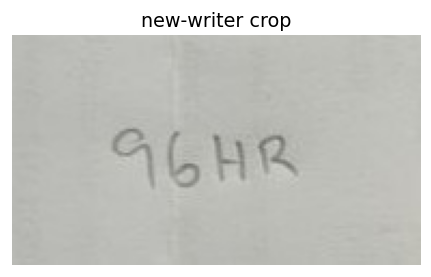

S0,96hr,0.0%
G0,96hir,25.0%


In [18]:
NW_ROOT = ASSIGNMENT / 'board2notes_newwriter_test_20261107/images'
def load_any(file):
    if file.startswith('newwriter__images__'):
        p = NW_ROOT / file[len('newwriter__images__'):]
        with Image.open(p) as im:
            return ImageOps.exif_transpose(im).convert('RGB').copy(), 'new-writer crop'
    return load_crop(file)

def show_pair2(st='new writers', before='S0', after='G0', index=0, order='Biggest improvement'):
    cols_ = ['file', 'label', 'pred', 'cer', 'cluster']
    a = d2[d2['set'].eq(st) & d2.model.eq(before)][cols_]; b = d2[d2['set'].eq(st) & d2.model.eq(after)][cols_]
    q = a.merge(b, on=['file', 'label', 'cluster'], suffixes=('_before', '_after'), validate='one_to_one')
    q['gain'] = q.cer_before - q.cer_after
    q = q.sort_values(['gain', 'file'], ascending=[order != 'Biggest improvement', True]).reset_index(drop=True)
    r = q.iloc[min(index, len(q) - 1)]
    print(f'{st} | {before} -> {after} | {order} #{index + 1} of {len(q)} | {r.cluster} | {r.file}')
    im, srcname = load_any(r.file)
    fig, ax = plt.subplots(figsize=(14, 2.6)); ax.imshow(im); ax.axis('off'); ax.set_title(srcname); plt.show()
    body = f'<p><b>Saved ground truth:</b> {html.escape(r.label)}</p><table style="text-align:left;width:100%">'
    for name, pred, cer in [(before, r.pred_before, r.cer_before), (after, r.pred_after, r.cer_after)]:
        body += (f'<tr><td style="padding:6px">{name}</td><td style="font:15px monospace">{coloured_reading(r.label, pred)}</td>'
                 f'<td>{cer:.1%}</td></tr>')
    display(HTML(body + '</table>'))

for i in range(3):
    show_pair2(index=i, order='Biggest improvement')
for i in range(2):
    show_pair2(index=i, order='Biggest regression')

### What this adds to the story

- **Model development, architecture side:** the pooling adaptation (section 4) is the large, robust result.
- **Model development, training side:** controlled two-seed ablations with a rule fixed before training. None of the four changes met the rule on whiteboard validation. The one mechanism-based change to how PP-OCRv5 trains its backbone (G0: let the CTC reader's loss train it) gave the clearest exploratory gain on unseen writers (~4 points, both seeds, both writers, every length), at the cost of more specialisation (IAM worse).
- **Main limitation, shown by data:** about 23–27% error on unseen writers versus 2–3% on new sentences in familiar handwriting. More writers in training is the most direct lever; a confirmation test on fresh writers is needed before claiming generalisation.

## 7c. The mobile reader (batch A, 10 Nov): why we chose the server reader

PP-OCRv5 has a smaller **mobile** recognizer (PPLCNetV3 backbone instead of PPHGNetV2). It is faster and smaller, and the teammate's first model was mobile, so we repeated our experiments on it (17 runs). **MC0** is the mobile control: the same training list as server **S0** (byte-identical), the same scoring, the same two-seed rule fixed before training. (MC0 is the mobile *control*; it is not the ladder's C0 in section 4c.)

Questions: (1) Is mobile good enough to replace the server reader? (2) Do any training changes help mobile? (3) Do the data and pooling findings hold on a second architecture?

**(1) Same data, same recipe: server vs mobile.** Mean line CER (%), lower is better.

,whiteboard val CER (%),CNN test CER (%),new writers CER (%),long sentences (held out) CER (%),IAM val CER (%)
server pretrained,15.48,45.79,43.08,30.93,12.20
mobile pretrained (start),20.58,56.30,32.32,5.40,18.71
server S0 (mean of 2 seeds),7.52,25.50,26.79,2.36,23.89
mobile MC0 (mean of 2 seeds),9.91,30.60,32.32,3.72,25.30
mobile minus server (control),2.39,5.10,5.53,1.35,1.41


**(2) Training changes on mobile, decided on whiteboard validation (mean of 2 seeds, vs MC0).** A change "helps" only if the whole interval is below 0 and both seeds agree.

,change,seed 1 (pp),seed 2 (pp),mean (pp),95% interval (pp),decision
setting,,,,,,
MG,guidance off,-0.94,-0.16,-0.55,-1.16 .. +0.08,improvement not established
ML,stage-wise backbone learning rates,-0.49,0.91,0.21,-0.30 .. +0.91,improvement not established
ME,extra SE attention block,0.97,0.55,0.76,+0.05 .. +1.66,hurts


**(3) The data and pooling questions repeated on mobile** (one seed; percentage points, 95% interval).

,change,whiteboard val,CNN test
comparison,,,
MV2 vs MV1b,our whiteboard crops vs IAM,"-9.36 [-14.01, -4.45] better","-22.62 [-25.16, -19.95] better"
MV2 vs MV2short,+ long lines (no copies),"+0.81 [-0.20, +1.61] no clear difference","-3.84 [-4.83, -2.86] better"
MV3short vs MV2short,"+ copies, short lines only","+0.09 [-0.88, +1.24] no clear difference","-2.77 [-3.93, -1.66] better"
MV3 vs MV2,"+ copies, short + long lines","+0.38 [-0.55, +1.06] no clear difference","+1.75 [+0.73, +2.66] worse"
MP128 vs MP40,training pooling only,"-30.41 [-32.85, -27.01] better","-34.96 [-39.36, -30.25] better"
MT vs MC1,teammate's Colab recipe vs PaddleOCR's original,"+33.03 [+28.71, +36.52] worse","+37.13 [+33.62, +40.54] worse"


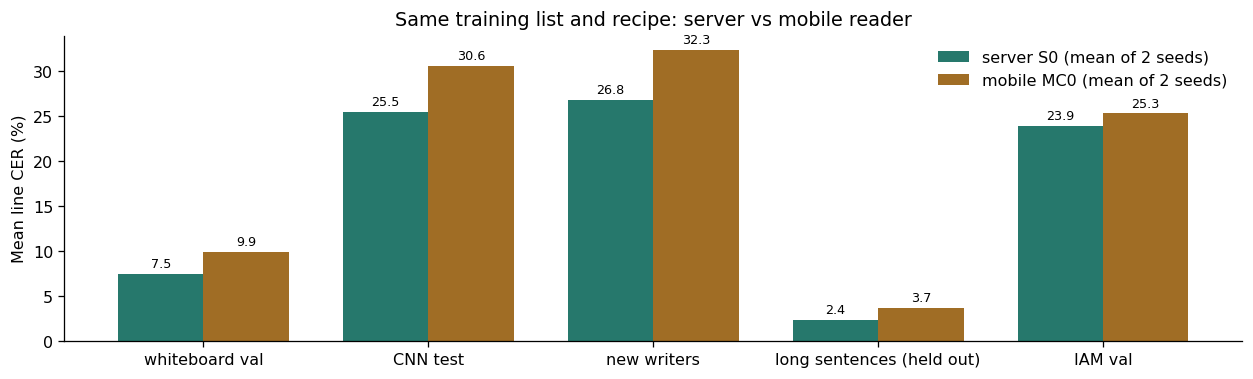

In [19]:
MOB = ASSIGNMENT / 'results_mobile_official_20261110'
dm = pd.read_csv(MOB / 'results/predictions.csv', keep_default_na=False)
mob = json.loads((MOB / 'results/summary.json').read_text())
CMP_SETS = ['whiteboard val', 'CNN test', 'new writers', 'long sentences (held out)', 'IAM val']
for st in CMP_SETS:
    assert set(zip(*[ds[ds.model.eq('S0') & ds['set'].eq(st)][k] for k in ('file', 'label')])) == \
           set(zip(*[dm[dm.model.eq('MC0') & dm['set'].eq(st)][k] for k in ('file', 'label')])), f'server and mobile scored different crops in {st}'
smean = ds.groupby(['model', 'set']).cer.mean() * 100
mmean = dm.groupby(['model', 'set']).cer.mean() * 100
two = lambda t, a, st: (t[(a, st)] + t[(a + 's2', st)]) / 2
arch = pd.DataFrame({st: {'server pretrained': smean[('pretrained', st)], 'mobile pretrained (start)': mmean[('start', st)],
                          'server S0 (mean of 2 seeds)': two(smean, 'S0', st), 'mobile MC0 (mean of 2 seeds)': two(mmean, 'MC0', st)}
                     for st in CMP_SETS})
arch.loc['mobile minus server (control)'] = arch.loc['mobile MC0 (mean of 2 seeds)'] - arch.loc['server S0 (mean of 2 seeds)']
display(Markdown('**(1) Same data, same recipe: server vs mobile.** Mean line CER (%), lower is better.'))
display(arch.rename(columns=lambda c: c + ' CER (%)').round(2))

prim = []
for t, what in [('MG', 'guidance off'), ('ML', 'stage-wise backbone learning rates'), ('ME', 'extra SE attention block')]:
    v = mob['mobile_verdicts'][f'primary {t}']
    prim.append({'setting': t, 'change': what, 'seed 1 (pp)': 100 * v['seed1'], 'seed 2 (pp)': 100 * v['seed2'],
                 'mean (pp)': 100 * v['diff'], '95% interval (pp)': f"{100 * v['lo']:+.2f} .. {100 * v['hi']:+.2f}", 'decision': v['verdict']})
display(Markdown('**(2) Training changes on mobile, decided on whiteboard validation (mean of 2 seeds, vs MC0).** '
                 'A change "helps" only if the whole interval is below 0 and both seeds agree.'))
display(pd.DataFrame(prim).set_index('setting').round(2))

rep = []
for a, b, what in [('MV2', 'MV1b', 'our whiteboard crops vs IAM'), ('MV2', 'MV2short', '+ long lines (no copies)'),
                   ('MV3short', 'MV2short', '+ copies, short lines only'), ('MV3', 'MV2', '+ copies, short + long lines'),
                   ('MP128', 'MP40', 'training pooling only'), ('MT', 'MC1', "teammate's Colab recipe vs PaddleOCR's original")]:
    row = {'comparison': f'{a} vs {b}', 'change': what}
    for st in ['whiteboard val', 'CNN test']:
        v = mob['comparisons'][f'{st}: {a} vs {b}']
        row[st] = f"{100 * v['diff']:+.2f} [{100 * v['lo']:+.2f}, {100 * v['hi']:+.2f}] {v['verdict']}"
    rep.append(row)
display(Markdown('**(3) The data and pooling questions repeated on mobile** (one seed; percentage points, 95% interval).'))
display(pd.DataFrame(rep).set_index('comparison'))

fig, ax = plt.subplots(figsize=(11, 3.4))
x = np.arange(len(CMP_SETS)); w = .38
for k, (row, colour) in enumerate([('server S0 (mean of 2 seeds)', '#26786c'), ('mobile MC0 (mean of 2 seeds)', '#a06d25')]):
    bars = ax.bar(x + (k - .5) * w, arch.loc[row, CMP_SETS], width=w, color=colour, label=row)
    ax.bar_label(bars, fmt='%.1f', padding=2, fontsize=8)
ax.set(xticks=x, xticklabels=CMP_SETS, ylabel='Mean line CER (%)', title='Same training list and recipe: server vs mobile reader')
ax.legend(frameon=False); fig.tight_layout(); plt.show()

**What batch A shows**

- **Mobile is consistently worse than server** on the same data and recipe: about 2–3 points on whiteboard validation and about 5 on the CNN board and new writers. This is the main reason the **server reader is the final reader**.
- Compare the **trained** rows (S0 vs MC0). The two pretrained rows are not a fair pair: the server model is read as downloaded (48 px), the mobile start with our 64 px reading setup. Note also that on new writers the trained mobile control is no better than its own starting weights (both about 32%).
- **No training change helped mobile by the rule.** Guidance off (MG) leaned better in both seeds but the interval crosses zero; stage-wise learning rates (ML) did nothing on validation and were worse on CNN; an extra SE block (ME) **hurt**.
- **The big findings repeat on a second architecture:** our crops beat IAM by a wide margin, and the pooling change is again worth about 30 points (MP128 vs MP40). A result that holds on two different networks is much stronger evidence than one run.
- **The teammate's Colab recipe (MT) is far worse** than PaddleOCR's original recipe on the same lines (about +33 points on validation), so the final model uses our recipe on his data (section 7d).
- Same caution as before: one seed for the data comparisons, and seed noise on mobile validation was about 0.9 points.

Batch B (mobile loss weights with guidance off: MGWlo, MGWlos2, MGWhi, MGWhis2) finished on 11 Nov; its scores are still on the pod and will be added here.

## 7d. The final model: S1his on the teammate's 80:10:10 split

The teammate needed a full working model, so the **server** reader was trained with the **S1 recipe** (64 × 1024, width / 8 pooling, stage-wise learning rates, guidance on) on **his dataset** (`TYW02/whiteboard-notes-v1`, revision 75619db2).

His original split put repeat photos of the same writing in both train and test, so we rebuilt it: every piece of writing (all its photos, near-identical labels, augmented copies) is one group, and whole groups go to one side; stratified 80:10:10 by source and line length. Validation (179 crops) picked the checkpoint; the test (169 crops) was scored once.

**Do not compare these numbers with the tables above.** It is different training data and a different test set. His dataset also contains our CNN board and validation boards (mostly in his train), so S1his must **never** be scored on our CNN or validation sets: a low score there would be leakage, not skill.

In [20]:
HIS = ASSIGNMENT / 'results_server_his_20261110'
dh = pd.read_csv(HIS / 'results/predictions.csv', keep_default_na=False)
his = json.loads((HIS / 'results/summary.json').read_text())
hs = his['summary']
tab = pd.DataFrame({st: {m: 100 * hs[f'{m} | {st}']['mean_line_CER'] for m in ['pretrained', 'S1his']} for st in ['his val', 'his test']})
tab.loc['S1his minus pretrained'] = tab.loc['S1his'] - tab.loc['pretrained']
display(Markdown(f"**Mean line CER (%) on the teammate's split.** Training lines: {his['his']['lines']['train_S1his']:,} "
                 f"(his augmented copies included); validation {his['his']['lines']['his_val']}, test {his['his']['lines']['his_test']}."))
display(tab.rename(columns=lambda c: c + ' CER (%)').round(2))
v = his['comparisons']['his test: S1his vs pretrained']
display(Markdown(f"Test: S1his vs pretrained **{100 * v['diff']:+.2f} points**, 95% interval {100 * v['lo']:+.2f} .. {100 * v['hi']:+.2f} "
                 f"(whole board photos resampled): {v['verdict']}."))
by_len = (dh[dh['set'].eq('his test')].groupby(['length', 'model']).cer.agg(['mean', 'size']).unstack('model'))
by_len = pd.DataFrame({'crops': by_len[('size', 'S1his')], 'pretrained CER (%)': 100 * by_len[('mean', 'pretrained')],
                       'S1his CER (%)': 100 * by_len[('mean', 'S1his')]}).reindex(['1-20 chars', '21-40 chars', 'over 40 chars'])
display(Markdown('**His test by line length:**')); display(by_len.round(2))

**Mean line CER (%) on the teammate's split.** Training lines: 8,493 (his augmented copies included); validation 179, test 169.

,his val CER (%),his test CER (%)
pretrained,18.24,16.90
S1his,6.21,7.04
S1his minus pretrained,-12.02,-9.86


Test: S1his vs pretrained **-9.86 points**, 95% interval -12.96 .. -6.75 (whole board photos resampled): better.

**His test by line length:**

,crops,pretrained CER (%),S1his CER (%)
length,,,
1-20 chars,92,15.77,6.16
21-40 chars,60,16.69,7.58
over 40 chars,17,23.76,9.91


**What this establishes:** on held-out writing from the teammate's own collection, fine-tuning with our recipe cuts the error from about 17% to about 7%. Long lines (over 40 characters) are the hardest group at about 10%, but there are only 17 of them, so that figure is rough. One seed; the test boards come from the same collection as training (different writing, often the same lectures), so this is not a test on new writers. A check on fresh photos by new writers is still the honest final test.

## 8. What was saved, and what does this establish?

The runs produced trained checkpoints on RunPod and exported inference models in the downloaded results. The export checks compare checkpoint and exported readings on a small validation fixture.

In [21]:
export_rows=[]
for model in DESCRIPTIONS:
    folder=RESULTS/'results/models'/f'PP-OCRv5_server_rec_board2notes_{model}'
    v=json.loads((folder/'verified.json').read_text())
    export_rows.append({'Run':model,'Fixture crops':v['fixture_crops'],
        'Matching readings (%)':100*v['identical_predictions'],
        'Export CER difference':v['mean_cer_difference'],
        'Inference parameters present':(folder/'inference.pdiparams').is_file()})
display(pd.DataFrame(export_rows).set_index('Run'))
display(Markdown('These are the **recorded RunPod checks**, not new inference on your Mac. '
    'They support using the exports with the tested height, resizing, dictionary and runtime policy. '
    'They do not automatically validate another inference engine, ONNX or INT8.'))

,Fixture crops,Matching readings (%),Export CER difference,Inference parameters present
Run,,,,
V1b,30,100.0,0.0,True
V2short,30,100.0,0.0,True
V3short,30,100.0,0.0,True
V2,30,100.0,0.0,True
V3,30,100.0,0.0,True
C1,30,100.0,0.0,True
P40,30,100.0,0.0,True
P128,30,100.0,0.0,True


These are the **recorded RunPod checks**, not new inference on your Mac. They support using the exports with the tested height, resizing, dictionary and runtime policy. They do not automatically validate another inference engine, ONNX or INT8.

In [22]:
extra = []
HIS_MODELS = ASSIGNMENT / 'results_server_his_20261110/results/models'
his_folder = next(p for p in [HIS_MODELS / 'PP-OCRv5_server_rec_board2notes_S1his', HIS_MODELS / 'PP-OCRv5_server_rec']
                  if (p / 'verified.json').is_file())   # the folder was renamed for the hand-over on 11 Nov
for name, folder in [('C0 (ladder)', ASSIGNMENT / 'results_server_c0_20261111/results/models/PP-OCRv5_server_rec_board2notes_C0'),
                     (f'S1his (final model, folder {his_folder.name})', his_folder)]:
    v = json.loads((folder / 'verified.json').read_text())
    if name.startswith('S1his'):
        assert v['identity']['checkpoint'].startswith('e39d161d3c53'), 'this folder is not the S1his export'
    extra.append({'Run': name, 'Fixture crops': v['fixture_crops'], 'Matching readings (%)': 100 * v['identical_predictions'],
                  'Export CER difference': v['mean_cer_difference'], 'Export height': v['identity']['export_h'],
                  'Inference parameters present': (folder / 'inference.pdiparams').is_file()})
display(Markdown('**Added 10-11 Nov:** the same export check for the ladder run and the final model. '
                 'S1his is the model to hand over: send its whole folder (inference.json, inference.pdiparams, inference.yml).'))
display(pd.DataFrame(extra).set_index('Run'))

**Added 10-11 Nov:** the same export check for the ladder run and the final model. S1his is the model to hand over: send its whole folder (inference.json, inference.pdiparams, inference.yml).

,Fixture crops,Matching readings (%),Export CER difference,Export height,Inference parameters present
Run,,,,,
C0 (ladder),30,100.0,0.0,48,True
"S1his (final model, folder PP-OCRv5_server_rec)",30,100.0,0.0,64,True


## 9. What we should do next

### Update, 11 Nov (supersedes points 2–3 below)

1. **Reader type:** the **server** reader (section 7c: mobile is consistently worse on the same data).
2. **Final model for the teammate:** **S1his**, trained on his leak-fixed 80:10:10 split (section 7d). For the app, choose between S1 (our split) and S1his after a short fresh-photo check by new writers.
3. **Story for the report** (section 4c): our data does most of the work; our recipe adds 2–3 points, but only when the wider input and the pooling change go together; pre-made copies add nothing on top of PaddleOCR's own augmentation.
4. **Still to add:** batch B scores (mobile loss weights with guidance off) once downloaded from the pod.
5. **Label fix:** `lecture_06_039` and `lecture_07_035` both show "4. ResNet" (same writing as `lecture_05_035`); correct them before any retraining.

### Plan as of 8 Nov (kept for the record)

1. **Keep all runs as evidence.** versions_2x2 (data and pooling questions, one seed), strategies_s0s3 and guide_g0 (training strategies, two seeds).
2. **Reader for the app:** S0 stays the formal reference (no setting met the pre-declared rule). **G0** is the leading candidate because of its new-writer result, with S1 second. State that it is chosen on exploratory evidence.
3. **Confirm on fresh handwriting:** 2–3 people who are not JH, DS or the team write a few lines on a whiteboard (≈30–50 crops). Declare "G0 vs S0" as the test **before** scoring, then score the exported models on the Mac (no retraining).
4. **More writers in training** is the most direct way to reduce the new-writer gap, if time allows.
5. **Freeze the reader and integrate the app:** with and without preprocessing (V4), then local/cloud deployment and optimisation.

Layer-wise LR, focal loss and guided training (GTC) are existing techniques. The contribution is choosing them from measured problems in this task and testing them with controlled, two-seed comparisons; describe them that way.

**Where to look again:**
- Section 2: the overall numbers (versions_2x2).
- Section 3: the images and model mistakes.
- Section 4: the pooling result (training vs reading slots); 4b: original vs adapted recipe; **4c: the step-by-step ladder (C0, 11 Nov).**
- Section 5: training over time.
- Section 6: long lines and augmentation; 6b: the IAM (out-of-domain) drop.
- Section 7: how CTC positions work.
- **Section 7b: training strategies (S0–S3, G0), seed noise, new writers, S0 vs G0 crops.**
- **Section 7c: the mobile reader (batch A); 7d: the final model S1his on the teammate's split.**

Full audits: `codex_update_20261107/REVIEW_BY_CODEX.md`, `codex_strategy_review_20261107/`, `results_guide_vs_s0/report.md`.